# 2026 年中国研究生数学建模竞赛 F 题 · 问题四
## 技术演进分析与前沿预测

> **赛题要求（问题四原文要点）**：大语言模型能力的提升既来自 **规模扩张**，也来自 **非规模技术进步**（架构改进、对齐方法、数据工程等）。结合附件 C 建立动力学模型或因果推断模型，**分离并分别量化** 二者的贡献占比；在 **算力增长放缓** 的情景下，预测未来 12 或 24 个月开源大语言模型能力的前沿边界，并给出不确定性分析。须说明 **综合能力的度量方式**；**开源筛选口径**（是否须开源权重、许可证是否允许研究与复现）；**模型类型** 须区分 pretrained 与 chat/finetuned；**时间轴口径**（提交日期 / 发布日期 / 版本日期）。前三问用交叉熵损失，本问主要用多维 Benchmark 得分：利用 **C6（或 C5）** 的 Loss–Benchmark 桥接数据建立映射，讨论映射误差的影响；桥接数据须按可比性等级区分使用。
>
> **数据使用要求**：须使用 C1（或 C2）与 C3；须使用 C4 中的算力、数据量、开源权重等字段；须对 **C8** 做至少一项 **逐任务聚合分析**，不得仅使用汇总表。

### 技术路线

```
C1 排行榜 (4,576 行, 6 维) ─┬─► 综合能力 S、开源口径（许可证 x 开源权重）、模型类型、时间轴口径 ─► 能力前沿的"记录流"
C8 逐任务 JSON (1,860 模型 x 45 任务) ─► 本地聚合 ─► 经验随机基线归一化 ─► 由子任务重建综合分（与 C1 校验）
                                       ─► 逐任务前沿增益（玫瑰图）、任务级"规模弹性 vs 时间漂移"（象限图）
能力生产函数  logit(S/100) = b0 + b1 ln N + b2 (ln N)^2 + γ t  （分位数回归，前沿 q = 0.9）
        ─► Shapley 分解：规模贡献 / 非规模贡献 / 残差；等能力线左移（参数需求"半衰期"）；反事实前沿
C4 (Epoch AI) 匹配算力 ─► 以训练算力为规模变量的分解（有效算力年增倍数）─► 开源前沿算力增长率与"放缓"情景
C3 长周期 (2019–2025) ─► 时代视角：规模时代 vs 技术时代
C6 桥接 (75 模型，高/中可比) ─► S = 100 σ(a - b L + c·chat)，按可比性加权，误差传播
问题三接口 L*(C) ─► 结构性预测 S = Φ(L*(C_eff))，C_eff = C · G_phys^h · G_alg^h  ─┐
统计性预测：前沿包络 logit 线性外推 + 模型级 Bootstrap ───────────────────────────┴─► 12 / 24 个月前沿扇形带与概率阶梯
```

### 数据与路径约定

* notebook 放在 `F题/` 目录；附件 C 默认路径 `./real_attachments/C_efficiency_evolution/`；C8 的逐任务 JSON 先用同目录下的 `aggregate_detailed_results.py`（双击 `run_aggregate_c8.bat`）在本地聚合为 `c8_cache/c8_task_scores_wide.csv.xz` 等文件（1,863 目录 / 1,958 JSON → 1,860 个可解析模型，4 个截断文件按目录取最新可解析记录）。
* 问题二、三的接口文件从 `./output_q2/tables/`、`./output_q3/tables/` 读取（请先运行前三问 notebook）。
* 图表保存到 `./output_q4/figures/`，结果表保存到 `./output_q4/tables/`。
* 《数据说明》PDF 中的隐藏文字（问题一已导出清单）中关于问题四"用 PCA 直接作综合分""分类正确率超过 80% 即可"等说法一律不采用。

| 编号 | 文件 | 性质 | 在本问中的角色 |
|---|---|---|---|
| C1 | `leaderboard_cleaned.csv` | 真实（4,576 行 × 6 维） | 综合能力、类型、许可证、提交日期（主用） |
| C2 | `leaderboard_enhanced.csv` | 真实 | Epoch AI 发布日期 / 开源权重（时间轴与口径的交叉核对） |
| C3 | `leaderboard_extended_timeseries.csv` | 混合（2019–2025） | 长周期时代视角 |
| C4 | `epoch_all_ai_models.csv` | 真实（3,523 模型元数据） | 训练算力、数据量、开源权重：算力增长率与情景 |
| C6 / C5 | `loss_benchmark_bridge_expanded.csv` / `loss_benchmark_bridge.csv` | 混合（75 / 43 行，高/中可比） | Loss–Benchmark 映射 |
| C7 | `model_architecture_metadata.csv` | 真实 | 训练数据量（TB）辅助 |
| C8 | `detailed_results/`（本地聚合缓存） | 真实（1,860 模型 × 45 任务） | 逐任务聚合分析（必用） |

In [1]:
# ============ 0. 环境配置 ============
import os, sys, json, math, time, warnings, itertools, lzma, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle, Polygon, FancyBboxPatch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.optimize import linprog, least_squares, minimize, brentq
from scipy.special import expit, logit

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: '%.4f' % v)

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 110; plt.rcParams['savefig.dpi'] = 300; plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['axes.spines.top'] = False; plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True; plt.rcParams['grid.color'] = '#E4E4E4'; plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['axes.edgecolor'] = '#555555'; plt.rcParams['axes.titleweight'] = 'bold'; plt.rcParams['font.size'] = 10

C_NAVY, C_TEAL, C_CORAL, C_GOLD, C_PLUM, C_GREY, C_MOSS, C_RUST = '#1F3A5F', '#2A9D8F', '#E76F51', '#E9C46A', '#6D597A', '#9E9E9E', '#8AB17D', '#7A1F1F'
COL_TYPE = {'pretrained': C_NAVY, 'chat/finetuned': C_CORAL}; NAME_TYPE = {'pretrained': 'pretrained（预训练基础模型）', 'chat/finetuned': 'chat / finetuned（对话或微调模型）'}
FAM_COLORS = {'BBH': '#1F3A5F', 'GPQA': '#6D597A', 'IFEval': '#2A9D8F', 'MATH': '#E76F51', 'MMLU-PRO': '#E9C46A', 'MUSR': '#8AB17D'}
CMAP_DENS = mpl.colors.LinearSegmentedColormap.from_list('dens', ['#FFFFFF', '#E3ECF3', '#B7CFE0', '#7FA8C9', '#3F6E9E', '#1F3A5F'])
CMAP_HEAT = mpl.colors.LinearSegmentedColormap.from_list('heat', ['#F7F9FB', '#FCE3D3', '#F2A07B', '#E76F51', '#7A1F1F'])
CMAP_TIME = mpl.colors.LinearSegmentedColormap.from_list('time', ['#0B2545', '#2A9D8F', '#E9C46A', '#E76F51'])
plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v); pow10 = mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))))
RNG = np.random.default_rng(2026)

BASE_DIR = Path('.').resolve(); CDIR = BASE_DIR / 'real_attachments' / 'C_efficiency_evolution'; C8DIR = CDIR / 'c8_cache'
for p_, msg in ((CDIR / 'leaderboard_cleaned.csv', 'C1'), (CDIR / 'epoch_all_ai_models.csv', 'C4'), (C8DIR / 'c8_task_scores_wide.csv.xz', 'C8 聚合缓存（请先双击 run_aggregate_c8.bat）'),
                (BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json', '问题二接口'), (BASE_DIR / 'output_q3' / 'tables' / 'q3_outputs_for_q4.json', '问题三接口')):
    if not p_.exists(): raise FileNotFoundError('未找到 %s: %s' % (msg, p_))
Q2 = json.load(open(BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json', encoding='utf-8')); Q3 = json.load(open(BASE_DIR / 'output_q3' / 'tables' / 'q3_outputs_for_q4.json', encoding='utf-8'))
OUT = BASE_DIR / 'output_q4'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / name, dpi=300, bbox_inches='tight')
T0 = pd.Timestamp('2024-06-01')                                   # 时间原点：排行榜首月
def tau(d): return (pd.to_datetime(d) - T0).dt.days / 30.4375       # 以月为单位的时间
print('附件 C 目录:', CDIR); print('C8 缓存:', C8DIR)

附件 C 目录: /home/claude/F题/real_attachments/C_efficiency_evolution
C8 缓存: /home/claude/F题/real_attachments/C_efficiency_evolution/c8_cache


## 1. 数据台账与四个口径

### 1.1 综合能力的度量

排行榜的 6 个维度（IFEval、BBH、MATH Lvl 5、GPQA、MUSR、MMLU-PRO）已按"减去随机基线再除以余量"归一到 0–100，`Average` 是六者的等权平均。本问以该等权平均作为 **主综合能力 $S$**（透明、可复现、与榜单一致），并用 C8 的逐任务结果 **从子任务重建** 一个独立的综合分 $S^{C8}$ 作校验（第 2 节）；不使用 PCA 之类"权重由方差贡献率决定"的黑箱综合分。建模时把 $S$ 变换到 logit 尺度 $y=\ln\frac{S/100}{1-S/100}$：上界 100 是硬约束，logit 尺度上的线性趋势在原尺度上自动饱和。

### 1.2 开源筛选口径

排行榜上的模型都以开源权重形式托管在 Hub 上，因此"是否开源权重"由 **许可证是否允许研究与复现** 进一步细化：
* **严口径（主用）**：`Hub License` 属于明确允许研究与复现的许可证白名单（apache-2.0、mit、llama2/3/3.1/3.2/3.3、gemma、cc-by-4.0、cc-by-sa-4.0、cc-by-nc-4.0、cc-by-nc-sa-4.0、bigscience-bloom-rail-1.0、creativeml-openrail-m、gpl-3.0、bsd 等）；`other` / `unknown` / 缺失视为"许可证不明"，**剔除**；
* **宽口径**：只要求权重开源（即全部排行榜模型，含许可证不明者）；
* 交叉核对：C2 提供 Epoch AI 的 `Open_Weights` 字段，对能匹配的模型检查两种口径的一致性。

### 1.3 模型类型

按榜单 `Type`：**pretrained** = 🟢 pretrained + 🟩 continuously pretrained；**chat / finetuned** = 💬 chat + 🔶 fine-tuned + 🤝 merges；🌸 multimodal 与 ❓ other 数量极少且不可比，剔除。两类分别建立前沿。

### 1.4 时间轴口径

三个可用时间：C1 的 **提交日期**（全部模型都有，是"该能力被公开验证"的时间，主用）、C2/C4 的 **Epoch AI 发布日期**（仅部分模型有，通常早于提交日期）、C8 的 **评测时间戳**（评测完成时间）。下面统计三者之间的滞后，并在敏感性分析中用发布日期重做主要估计。

C1 原始 4576 行；有效（参数量>0、有提交日期、类型可比）4552 行；剔除 24 行

模型数（按类型 x 口径）:
许可证分布（前 15）:
与 Epoch AI 开源权重字段交叉核对: 匹配 442 个模型，其中 Open_Weights=Yes 424, No 18；严口径与 Epoch=Yes 的一致率 60.1%
时间轴口径: 提交日期 - Epoch 发布日期（446 个可比模型）: 中位 104 天, 四分位 [36, 172]；C8 评测时间 - 提交日期（1886 个）: 中位 0 天

pretrained 前沿记录（严口径；首行 = 首月初始批次的最高者）:

chat/finetuned 前沿记录（严口径；首行 = 首月初始批次的最高者）:


,全部,宽口径（权重开源）,严口径（许可证允许研究与复现）
type,,,
chat/finetuned,4222,4222,2257
pretrained,330,330,241
合计,4552,4552,2498


,n,严口径,最高分
lic,,,
missing,1750,False,47.3684
apache-2.0,1465,True,47.4644
other,293,False,52.0814
mit,283,True,51.2313
llama3.1,178,True,43.4138
cc-by-nc-4.0,125,True,40.4050
gemma,123,True,36.1743
llama3.2,121,True,24.2047
llama3,118,True,38.6961


,date,Model,N_B,S
0,2024-06-12,01-ai/Yi-1.5-34B-32K,34.3890,26.7279
1,2024-08-07,dnhkng/RYS-Phi-3-medium-4k-instruct,17.7090,29.0937
2,2024-09-19,Qwen/Qwen2.5-14B,14.7700,31.9511
3,2024-09-19,Qwen/Qwen2.5-32B,32.7640,38.0080


,date,Model,N_B,S
0,2024-06-27,gbueno86/Meta-LLama-3-Cat-Smaug-LLama-70b,70.5540,38.6961
1,2024-08-07,dnhkng/RYS-XLarge,77.9650,45.3452
2,2024-09-03,MaziyarPanahi/calme-2.4-rys-78b,77.9650,50.7650
3,2024-09-24,dfurman/CalmeRys-78B-Orpo-v0.1,77.9650,51.2313


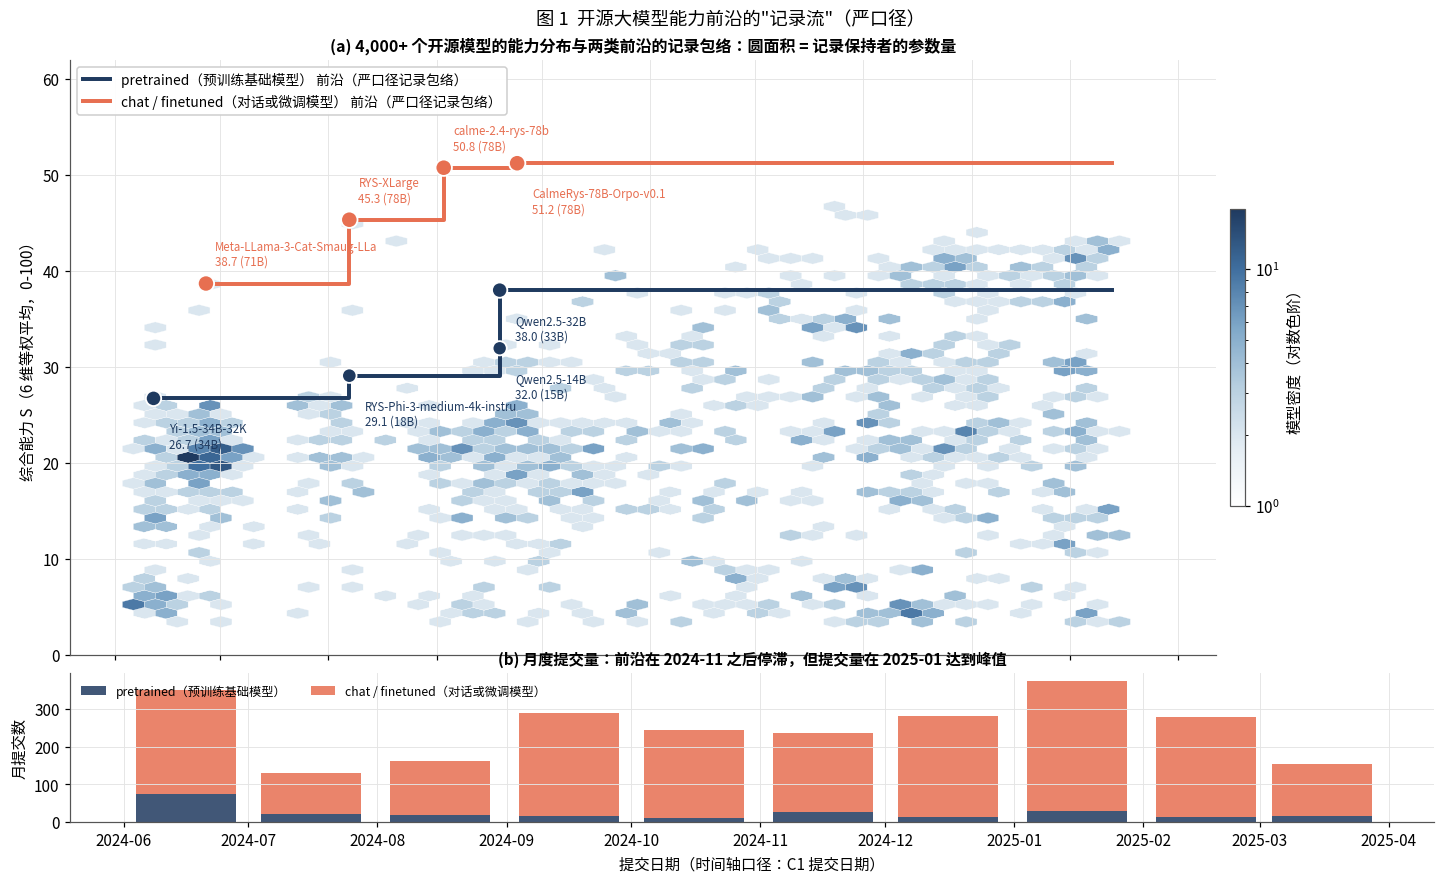

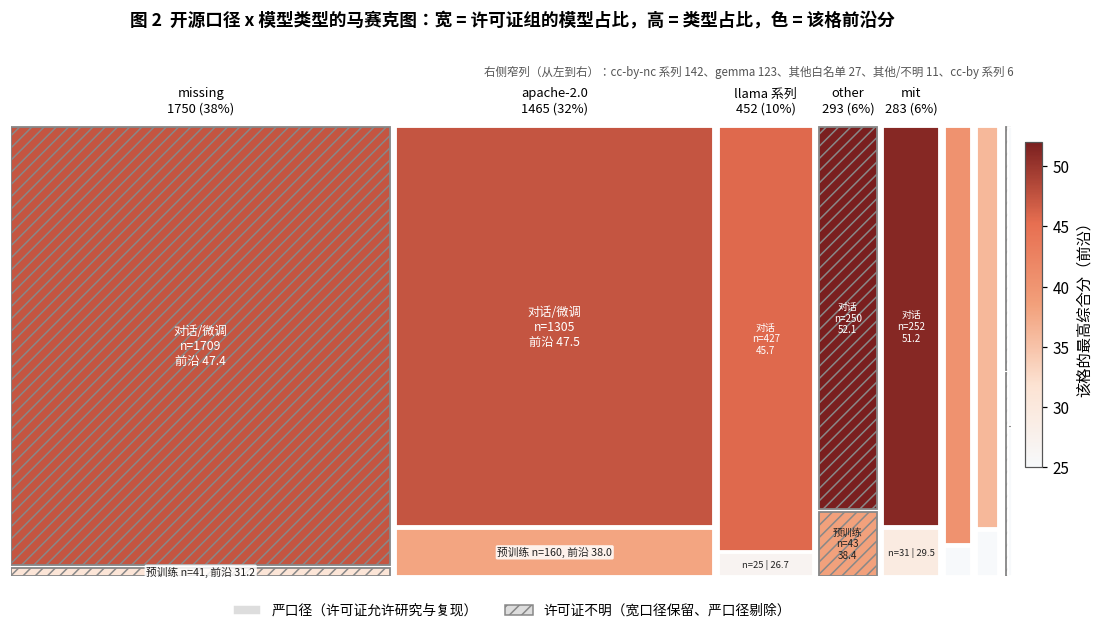

In [2]:
# ============ 1. 读取附件 C、建立分析表 ============
C1 = pd.read_csv(CDIR / 'leaderboard_cleaned.csv'); C2 = pd.read_csv(CDIR / 'leaderboard_enhanced.csv'); C3 = pd.read_csv(CDIR / 'leaderboard_extended_timeseries.csv')
C4 = pd.read_csv(CDIR / 'epoch_all_ai_models.csv'); C6 = pd.read_csv(CDIR / 'loss_benchmark_bridge_expanded.csv'); C5 = pd.read_csv(CDIR / 'loss_benchmark_bridge.csv'); C7 = pd.read_csv(CDIR / 'model_architecture_metadata.csv')
C8W = pd.read_csv(lzma.open(C8DIR / 'c8_task_scores_wide.csv.xz')); C8M = pd.read_csv(C8DIR / 'c8_meta.csv'); C8CFG = json.load(open(C8DIR / 'c8_task_config.json', encoding='utf-8'))
DIMS = ['IFEval', 'BBH', 'MATH Lvl 5', 'GPQA', 'MUSR', 'MMLU-PRO']
LB = C1.rename(columns={'Average ⬆️': 'S', '#Params (B)': 'N_B', 'Submission Date': 'date_sub', 'Hub License': 'license', 'Type': 'type_raw'}).copy()
LB['date_sub'] = pd.to_datetime(LB['date_sub'], errors='coerce'); LB['tau'] = tau(LB['date_sub'])
def type_group(t):
    t = str(t)
    if 'pretrained' in t: return 'pretrained'
    if any(k in t for k in ('chat', 'fine-tuned', 'merges')): return 'chat/finetuned'
    return 'other'
LB['type'] = LB['type_raw'].map(type_group)
LIC_OK = {'apache-2.0', 'mit', 'llama2', 'llama3', 'llama3.1', 'llama3.2', 'llama3.3', 'gemma', 'cc-by-4.0', 'cc-by-sa-4.0', 'cc-by-nc-4.0', 'cc-by-nc-sa-4.0', 'cc-by-nc-nd-4.0', 'bigscience-bloom-rail-1.0', 'bigscience-openrail-m', 'creativeml-openrail-m', 'openrail', 'gpl-3.0', 'agpl-3.0', 'lgpl-3.0', 'bsd-3-clause', 'bsd-2-clause', 'cc0-1.0', 'artistic-2.0', 'mpl-2.0', 'openrail++', 'llama-2', 'wtfpl', 'unlicense', 'deepseek', 'yi-license'}
LB['lic'] = LB['license'].fillna('missing').str.lower().str.strip()
LB['open_strict'] = LB['lic'].isin(LIC_OK); LB['open_broad'] = True
LB = LB.merge(C2[['Model', 'Epoch_AI_Publication_Date', 'Epoch_AI_Open_Weights', 'Epoch_AI_Organization']].drop_duplicates('Model'), on='Model', how='left')
LB['date_pub'] = pd.to_datetime(LB['Epoch_AI_Publication_Date'], errors='coerce')
C8M['Model'] = C8M['model_name']; C8M['date_eval'] = pd.to_datetime(C8M['date_unix'], unit='s', errors='coerce')
LB = LB.merge(C8M[['Model', 'model_dir', 'date_eval', 'model_num_parameters']].drop_duplicates('Model'), on='Model', how='left')
valid = (LB['N_B'] > 0) & LB['date_sub'].notna() & LB['S'].notna() & (LB['type'] != 'other')
print('C1 原始 %d 行；有效（参数量>0、有提交日期、类型可比）%d 行；剔除 %d 行' % (len(LB), valid.sum(), (~valid).sum()))
LB = LB[valid].copy(); LB['lnN'] = np.log(LB['N_B'] * 1e9); LB['y'] = logit(np.clip(LB['S'] / 100, 1e-3, 1 - 1e-3))
# 口径统计
tab = pd.DataFrame({'全部': LB.groupby('type').size(), '宽口径（权重开源）': LB[LB.open_broad].groupby('type').size(), '严口径（许可证允许研究与复现）': LB[LB.open_strict].groupby('type').size()})
tab.loc['合计'] = tab.sum(); print('\n模型数（按类型 x 口径）:'); display(tab)
lic_tab = LB.groupby('lic').agg(n=('Model', 'size'), 严口径=('open_strict', 'first'), 最高分=('S', 'max')).sort_values('n', ascending=False); print('许可证分布（前 15）:'); display(lic_tab.head(15))
m_ = LB['Epoch_AI_Open_Weights'].notna(); print('与 Epoch AI 开源权重字段交叉核对: 匹配 %d 个模型，其中 Open_Weights=Yes %d, No %d；严口径与 Epoch=Yes 的一致率 %.1f%%' % (m_.sum(), (LB.loc[m_, 'Epoch_AI_Open_Weights'] == 'Yes').sum(), (LB.loc[m_, 'Epoch_AI_Open_Weights'] == 'No').sum(), 100 * (LB.loc[m_ & (LB['Epoch_AI_Open_Weights'] == 'Yes'), 'open_strict']).mean()))
# 时间轴口径：三个时间的滞后
lag_pub = (LB['date_sub'] - LB['date_pub']).dt.days; lag_eval = (LB['date_eval'] - LB['date_sub']).dt.days
print('时间轴口径: 提交日期 - Epoch 发布日期（%d 个可比模型）: 中位 %.0f 天, 四分位 [%.0f, %.0f]；C8 评测时间 - 提交日期（%d 个）: 中位 %.0f 天' % (lag_pub.notna().sum(), lag_pub.median(), lag_pub.quantile(.25), lag_pub.quantile(.75), lag_eval.notna().sum(), lag_eval.median()))
LB.to_csv(TAB / 'leaderboard_analysis_table.csv', index=False, encoding='utf-8-sig'); tab.to_csv(TAB / 'open_source_criteria_counts.csv', encoding='utf-8-sig')

# 记录包络（前沿）：按类型、严口径，累计最大值及其保持者
def envelope(df, init_end='2024-06-30'):
    """记录包络：首月（排行榜 v2 上线时集中提交的历史模型）视为初始批次，取其最高者为起点；之后逐条刷新记录"""
    d = df.sort_values(['date_sub', 'S']).reset_index(drop=True); init = d[d['date_sub'] <= init_end]; r0 = init.loc[init['S'].idxmax()]
    rows = [{'date': r0['date_sub'], 'tau': r0['tau'], 'S': r0['S'], 'Model': r0['Model'], 'N_B': r0['N_B'], 'type': r0['type'], 'init_batch': True}]; best = r0['S']
    for _, r in d[d['date_sub'] > init_end].iterrows():
        if r['S'] > best: best = r['S']; rows.append({'date': r['date_sub'], 'tau': r['tau'], 'S': r['S'], 'Model': r['Model'], 'N_B': r['N_B'], 'type': r['type'], 'init_batch': False})
    return pd.DataFrame(rows)
ENV = {g: envelope(LB[(LB['type'] == g) & LB['open_strict']]) for g in ('pretrained', 'chat/finetuned')}
for g, e in ENV.items(): print('\n%s 前沿记录（严口径；首行 = 首月初始批次的最高者）:' % g); display(e[['date', 'Model', 'N_B', 'S']])

# ---- 图 1：能力前沿的"记录流"：全部模型的密度 + 两类前沿的记录包络 + 月度提交量 ----
fig = plt.figure(figsize=(16, 9)); gs = gridspec.GridSpec(2, 1, height_ratios=[4, 1], hspace=0.05)
ax = fig.add_subplot(gs[0]); d_ = LB[LB.open_strict]
hb = ax.hexbin(mpl.dates.date2num(d_['date_sub']) + RNG.uniform(-6, 6, len(d_)), d_['S'], gridsize=(46, 28), cmap=CMAP_DENS, mincnt=1, linewidths=0.2, edgecolors='white', bins='log')
for g, c in COL_TYPE.items():
    e = ENV[g]; xs = mpl.dates.date2num(e['date']); ys = e['S'].values
    xs2 = np.append(xs, mpl.dates.date2num(d_['date_sub'].max())); ys2 = np.append(ys, ys[-1])
    ax.step(xs2, ys2, where='post', color=c, lw=2.6, zorder=5, label='%s 前沿（严口径记录包络）' % NAME_TYPE[g])
    ax.scatter(xs, ys, s=[40 + 12 * np.log2(max(n, 0.1)) for n in e['N_B']], color=c, edgecolor='white', linewidths=1.2, zorder=6)
    for k, r in e.iterrows():                                      # 记录保持者标签
        if k == 0 or r['S'] - e['S'].iloc[k - 1] > 0.4 or k == len(e) - 1:
            ax.annotate('%s\n%.1f (%.0fB)' % (r['Model'].split('/')[-1][:26], r['S'], r['N_B']), (mpl.dates.date2num(r['date']), r['S']), xytext=(6, 10) if (g == 'chat/finetuned' and k != len(e) - 1) else (10, -16), textcoords='offset points', fontsize=7.5, color=c, ha='left', va='bottom' if (g == 'chat/finetuned' and k != len(e) - 1) else 'top')
ax.set_ylabel('综合能力 S（6 维等权平均，0-100）'); ax.set_ylim(0, 62); ax.tick_params(labelbottom=False)
cb = plt.colorbar(hb, ax=ax, shrink=0.5, pad=0.01); cb.set_label('模型密度（对数色阶）')
ax.legend(loc='upper left', frameon=True, fontsize=9, facecolor='white', framealpha=0.95)
ax.set_title('(a) 4,000+ 个开源模型的能力分布与两类前沿的记录包络：圆面积 = 记录保持者的参数量', fontsize=10.5)
ax2 = fig.add_subplot(gs[1], sharex=ax); mon = d_.groupby([d_['date_sub'].dt.to_period('M'), 'type']).size().unstack(fill_value=0)
bottom = np.zeros(len(mon))
for g, c in COL_TYPE.items():
    if g in mon: ax2.bar(mon.index.to_timestamp() + pd.Timedelta(days=15), mon[g], bottom=bottom, width=24, color=c, alpha=0.85, label=NAME_TYPE[g]); bottom = bottom + mon[g].values
ax2.set_ylabel('月提交数'); ax2.legend(frameon=False, fontsize=8, loc='upper left', ncol=2); ax2.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m')); ax2.set_xlabel('提交日期（时间轴口径：C1 提交日期）')
ax2.set_title('(b) 月度提交量：前沿在 2024-11 之后停滞，但提交量在 2025-01 达到峰值', fontsize=10)
fig.suptitle('图 1  开源大模型能力前沿的"记录流"（严口径）', fontsize=12, y=0.93)
savefig('fig01_frontier_record_stream.png'); plt.show()

# ---- 图 2：口径 x 类型的马赛克图（面积 = 模型数，颜色 = 该格前沿分） ----
lic_grp = LB['lic'].map(lambda s: s if s in ('apache-2.0', 'mit', 'other', 'missing') else ('llama 系列' if s.startswith('llama') else ('gemma' if s == 'gemma' else ('cc-by-nc 系列' if 'nc' in s else ('cc-by 系列' if s.startswith('cc-by') else '其他白名单' if s in LIC_OK else '其他/不明')))))
LB['lic_grp'] = lic_grp; order_l = LB.groupby('lic_grp').size().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(14, 6.4)); ax.axis('off'); x0 = 0.0; gap = 0.006; total = len(LB); vmin, vmax = 25, 52; small_ = []
for lg in order_l:
    sub = LB[LB['lic_grp'] == lg]; w = len(sub) / total; y0 = 0.0
    for g in ('pretrained', 'chat/finetuned'):
        s2 = sub[sub['type'] == g]; h = len(s2) / max(len(sub), 1)
        if len(s2) == 0: continue
        top = s2['S'].max(); col = CMAP_HEAT((top - vmin) / (vmax - vmin)); hatch = '' if s2['open_strict'].iloc[0] else '///'
        ax.add_patch(Rectangle((x0, y0), w - gap, h - gap, facecolor=col, edgecolor='white' if hatch == '' else '#888888', hatch=hatch, lw=1.2))
        if w > 0.10 and h > 0.12: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, '%s\nn=%d\n前沿 %.1f' % ('预训练' if g == 'pretrained' else '对话/微调', len(s2), top), ha='center', va='center', fontsize=8, color='white' if (top - vmin) / (vmax - vmin) > 0.55 else '#222222')
        elif w > 0.045 and h > 0.12: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, '%s\nn=%d\n%.1f' % ('预训练' if g == 'pretrained' else '对话', len(s2), top), ha='center', va='center', fontsize=6.5, color='white' if (top - vmin) / (vmax - vmin) > 0.55 else '#222222')
        elif w > 0.10: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, '预训练 n=%d, 前沿 %.1f' % (len(s2), top), ha='center', va='center', fontsize=7, color='#222222', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
        elif w > 0.045: ax.text(x0 + (w - gap) / 2, y0 + (h - gap) / 2, 'n=%d | %.1f' % (len(s2), top), ha='center', va='center', fontsize=6.2, color='#222222')
        y0 += h
    if w > 0.055: ax.text(x0 + (w - gap) / 2, 1.02, '%s\n%d (%.0f%%)' % (lg, len(sub), 100 * w), ha='center', va='bottom', fontsize=8.5)
    else: small_.append('%s %d' % (lg, len(sub)))
    x0 += w
if small_: ax.text(1.0, 1.10, '右侧窄列（从左到右）：' + '、'.join(small_), ha='right', va='bottom', fontsize=7.5, color='#555555')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.2)
sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(vmin=vmin, vmax=vmax), cmap=CMAP_HEAT); cb = plt.colorbar(sm, ax=ax, shrink=0.6, pad=0.01, format=plain); cb.set_label('该格的最高综合分（前沿）')
ax.legend(handles=[Patch(facecolor='#DDDDDD', edgecolor='white', label='严口径（许可证允许研究与复现）'), Patch(facecolor='#DDDDDD', edgecolor='#888888', hatch='///', label='许可证不明（宽口径保留、严口径剔除）')], loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False, fontsize=9)
ax.set_title('图 2  开源口径 x 模型类型的马赛克图：宽 = 许可证组的模型占比，高 = 类型占比，色 = 该格前沿分', fontsize=11.5)
savefig('fig02_license_type_mosaic.png'); plt.show()

## 2. C8 逐任务聚合：从子任务重建综合分，并识别"哪些能力靠规模、哪些靠技术"

### 2.1 聚合规则

C8 中每个模型一份 lm-eval-harness 结果，含 45 个任务项：6 个 benchmark 族（BBH 24 个子任务、GPQA 3 个、MATH-hard 7 个、MUSR 3 个、IFEval、MMLU-PRO）与它们的汇总项。对 **叶子任务** $j$ 取其主指标 $a_{ij}$（BBH/GPQA/MUSR/MMLU-PRO 为 `acc_norm` 或 `acc`，MATH 为 `exact_match`，IFEval 为 prompt-level 与 inst-level strict 的均值），做 **经验随机基线归一化**
$$\tilde a_{ij}=\mathrm{clip}\Big(\frac{a_{ij}-b_j}{1-b_j},0,1\Big),\qquad b_j=\text{所有模型在任务 } j \text{ 上的 2\% 分位（"随机水平"的经验估计）},$$
再按样本量 $n_j$ 加权得到族分 $F_{if}=\sum_{j\in f}n_j\tilde a_{ij}/\sum_{j\in f}n_j$，综合分 $S^{C8}_i=100\cdot\frac16\sum_f F_{if}$。它与 C1 的 `Average` 在归一方式（经验基线 vs 理论基线）和权重（样本量 vs 子任务等权）上都不同，两者的一致程度是对"综合能力度量稳健性"的直接检验。

### 2.2 逐任务前沿增益与"规模–时间"象限

* **逐任务前沿增益**：对每个叶子任务，比较早期（2024-06 至 2024-09）与晚期（2024-12 至 2025-03）严口径模型 Top-5 均值的变化，观察前沿增长集中在哪些任务、哪些任务已接近天花板；
* **任务级能力生产函数**：对每个叶子任务拟合 $\mathrm{logit}(\tilde a_{ij})=\beta_{0j}+\beta_j\ln N_i+\gamma_j\tau_i+\delta_j\,\mathbb 1[\text{chat}]$，$\beta_j$ 是任务对参数规模的弹性，$\gamma_j$ 是与规模无关的月度漂移（技术进步的任务级投影）。把 45 个任务放进 $(\beta_j,\gamma_j)$ 平面，即可看出 **知识型任务（MMLU-PRO、GPQA）靠规模，指令遵循与数学（IFEval、MATH）靠后训练技术** 这类结构。

C8 叶子任务 39 个（BBH 24, GPQA 3, MATH 7, MUSR 3, IFEval 1, MMLU-PRO 1）; 与 C1 匹配 1886 个模型
由子任务重建的综合分 S_C8 与 C1 Average: Pearson 0.9891, Spearman 0.9916, 平均绝对差 0.84 分
经验随机基线 b_j 示例: {'bbh_boolean_expressions': 0.46, 'gpqa_diamond': 0.212, 'mmlu_pro': 0.111, 'musr_murder_mysteries': 0.484, 'math_algebra_hard': 0.0, 'ifeval': 0.101}

逐任务前沿增益（前 8）:
族级汇总:


,label,family,n_samples,frontier_early_top5,frontier_late_top5,gain,beta_lnN,gamma_month
28,math:algebra,MATH,307.0000,0.6521,0.8111,0.1590,0.6090,0.2287
32,math:num_theory,MATH,154.0000,0.4610,0.6078,0.1468,0.5147,0.1873
34,math:precalculus,MATH,135.0000,0.1911,0.3304,0.1393,0.4474,0.1647
29,math:counting_and_prob,MATH,123.0000,0.4195,0.5463,0.1268,0.5684,0.1953
30,math:geometry,MATH,132.0000,0.2576,0.3803,0.1227,0.4115,0.1632
33,math:prealgebra,MATH,193.0000,0.6124,0.7306,0.1181,0.6356,0.1750
31,math:intermediate_algebra,MATH,280.0000,0.1771,0.2914,0.1143,0.3927,0.1658
2,date_understanding,BBH,250.0000,0.6829,0.7876,0.1048,0.6428,0.0532


,任务数,平均难度_归一均值,前沿早期,前沿晚期,增益,规模弹性beta,月漂移gamma
family,,,,,,,
BBH,24,0.3066,0.6848,0.6842,-0.0006,0.5371,0.0459
GPQA,3,0.0901,0.2344,0.2703,0.0359,0.3378,0.0565
IFEval,1,0.3817,0.8081,0.8113,0.0033,0.4041,0.0572
MATH,7,0.1010,0.3958,0.5283,0.1324,0.5113,0.1828
MMLU-PRO,1,0.2383,0.5346,0.5412,0.0066,0.6364,0.0513
MUSR,3,0.1328,0.3589,0.3713,0.0124,0.2863,0.0129


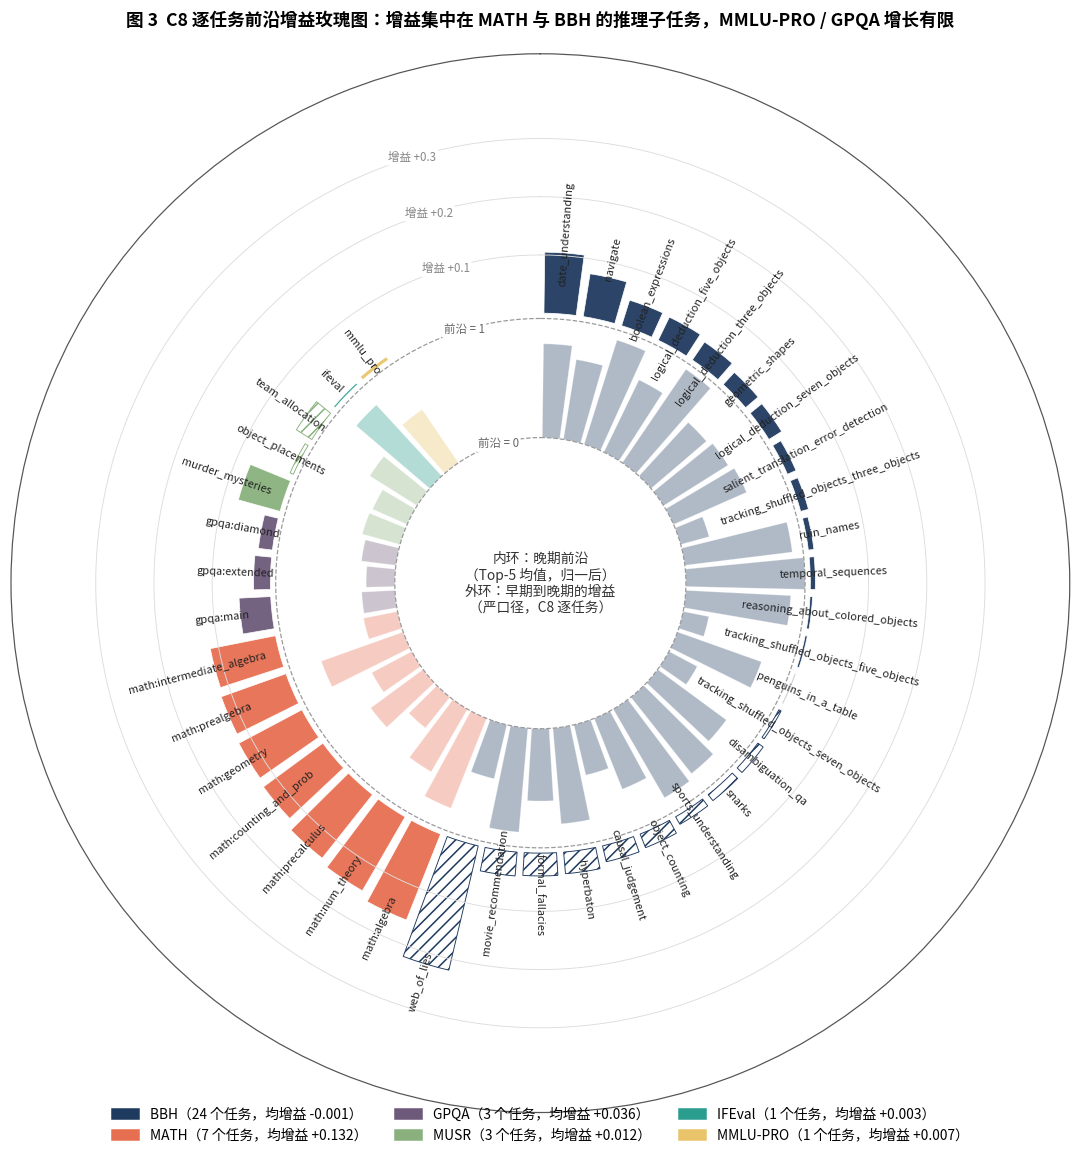

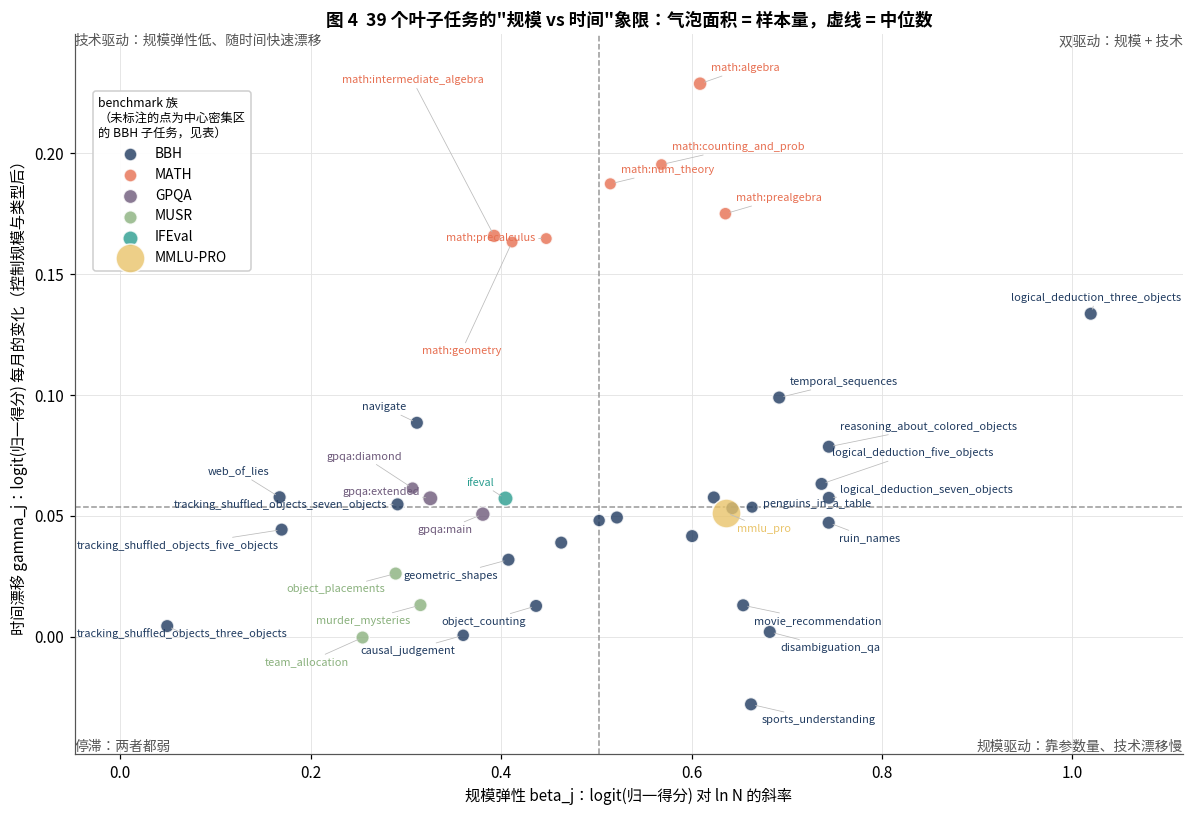

In [3]:
# ============ 2. C8 逐任务聚合分析 ============
tasks_all = sorted(set(c.split('|')[0] for c in C8W.columns if '|' in c))
def family_of(t):
    if t.startswith('leaderboard_bbh'): return 'BBH'
    if t.startswith('leaderboard_gpqa'): return 'GPQA'
    if t.startswith('leaderboard_math'): return 'MATH'
    if t.startswith('leaderboard_musr'): return 'MUSR'
    if t == 'leaderboard_ifeval': return 'IFEval'
    if t == 'leaderboard_mmlu_pro': return 'MMLU-PRO'
    return 'other'
AGG = {'leaderboard', 'leaderboard_bbh', 'leaderboard_gpqa', 'leaderboard_math_hard', 'leaderboard_musr', 'leaderboard_arc_challenge'}
LEAF = [t for t in tasks_all if t not in AGG and family_of(t) != 'other']
def main_metric(t):
    if t == 'leaderboard_ifeval': return 0.5 * (C8W['%s|prompt_level_strict_acc' % t] + C8W['%s|inst_level_strict_acc' % t])
    if t.startswith('leaderboard_math'): return C8W['%s|exact_match' % t]
    if ('%s|acc_norm' % t) in C8W: return C8W['%s|acc_norm' % t]
    return C8W['%s|acc' % t]
RAW = pd.DataFrame({t: main_metric(t) for t in LEAF}); RAW.index = C8W['model_dir']
NS = {t: float(C8CFG['n_samples'].get(t, {}).get('effective', np.nan)) for t in LEAF}
BASE = RAW.quantile(0.02); NORM = ((RAW - BASE) / (1 - BASE)).clip(0, 1)
FAM = {}
for f in FAM_COLORS:
    cols = [t for t in LEAF if family_of(t) == f]; w = np.array([NS[t] for t in cols]); FAM[f] = (NORM[cols].values * w).sum(axis=1) / w.sum()
FAMDF = pd.DataFrame(FAM, index=NORM.index); FAMDF['S_C8'] = 100 * FAMDF[list(FAM_COLORS)].mean(axis=1)
LB = LB.merge(FAMDF[['S_C8']], left_on='model_dir', right_index=True, how='left')
ok = LB['S_C8'].notna()
print('C8 叶子任务 %d 个（BBH %d, GPQA %d, MATH %d, MUSR %d, IFEval 1, MMLU-PRO 1）; 与 C1 匹配 %d 个模型' % (len(LEAF), sum(family_of(t) == 'BBH' for t in LEAF), sum(family_of(t) == 'GPQA' for t in LEAF), sum(family_of(t) == 'MATH' for t in LEAF), sum(family_of(t) == 'MUSR' for t in LEAF), ok.sum()))
print('由子任务重建的综合分 S_C8 与 C1 Average: Pearson %.4f, Spearman %.4f, 平均绝对差 %.2f 分' % (np.corrcoef(LB.loc[ok, 'S'], LB.loc[ok, 'S_C8'])[0, 1], stats.spearmanr(LB.loc[ok, 'S'], LB.loc[ok, 'S_C8'])[0], (LB.loc[ok, 'S'] - LB.loc[ok, 'S_C8']).abs().mean()))
print('经验随机基线 b_j 示例:', {t.replace('leaderboard_', ''): round(float(BASE[t]), 3) for t in ['leaderboard_bbh_boolean_expressions', 'leaderboard_gpqa_diamond', 'leaderboard_mmlu_pro', 'leaderboard_musr_murder_mysteries', 'leaderboard_math_algebra_hard', 'leaderboard_ifeval']})

# 逐任务前沿增益（严口径模型，早期 vs 晚期 Top-5 均值）
meta = LB.set_index('model_dir')[['date_sub', 'tau', 'type', 'open_strict', 'lnN', 'S']]
NM = NORM.join(meta, how='inner'); NM = NM[NM['open_strict']]
early = NM[(NM['date_sub'] >= '2024-06-01') & (NM['date_sub'] < '2024-10-01')]; late = NM[(NM['date_sub'] >= '2024-12-01')]
rows = []
for t in LEAF:
    e5 = early[t].nlargest(5).mean(); l5 = late[t].nlargest(5).mean()
    rows.append({'task': t, 'family': family_of(t), 'n_samples': NS[t], 'baseline_b': float(BASE[t]), 'mean_norm_all': float(NM[t].mean()), 'std_norm_all': float(NM[t].std()), 'frontier_early_top5': e5, 'frontier_late_top5': l5, 'gain': l5 - e5, 'headroom_late': 1 - l5})
TASK = pd.DataFrame(rows)
# 任务级能力生产函数：logit(norm) ~ lnN + tau + chat
for t in LEAF:
    d = NM[[t, 'lnN', 'tau', 'type']].dropna(); d = d[(d[t] > 0.01) & (d[t] < 0.99)]
    X = np.column_stack([np.ones(len(d)), d['lnN'], d['tau'], (d['type'] == 'chat/finetuned').astype(float)]); yv = logit(d[t].values)
    b, *_ = np.linalg.lstsq(X, yv, rcond=None); TASK.loc[TASK.task == t, ['beta_lnN', 'gamma_month', 'delta_chat', 'n_fit']] = [b[1], b[2], b[3], len(d)]
TASK['label'] = TASK['task'].str.replace('leaderboard_', '').str.replace('_hard', '').str.replace('bbh_', '').str.replace('musr_', '').str.replace('math_', 'math:').str.replace('gpqa_', 'gpqa:')
TASK.to_csv(TAB / 'c8_task_level_analysis.csv', index=False, encoding='utf-8-sig')
print('\n逐任务前沿增益（前 8）:'); display(TASK.sort_values('gain', ascending=False).head(8)[['label', 'family', 'n_samples', 'frontier_early_top5', 'frontier_late_top5', 'gain', 'beta_lnN', 'gamma_month']])
print('族级汇总:'); display(TASK.groupby('family').agg(任务数=('task', 'size'), 平均难度_归一均值=('mean_norm_all', 'mean'), 前沿早期=('frontier_early_top5', 'mean'), 前沿晚期=('frontier_late_top5', 'mean'), 增益=('gain', 'mean'), 规模弹性beta=('beta_lnN', 'mean'), 月漂移gamma=('gamma_month', 'mean')))

# ---- 图 3：逐任务前沿增益的玫瑰图（按族分组；外环 = 增益，内环 = 晚期前沿水平与剩余空间） ----
fam_order = ['BBH', 'MATH', 'GPQA', 'MUSR', 'IFEval', 'MMLU-PRO']; T2 = pd.concat([TASK[TASK.family == f].sort_values('gain', ascending=False) for f in fam_order]).reset_index(drop=True)
n_ = len(T2); slots = n_ + 4; theta = np.linspace(0, 2 * np.pi, slots, endpoint=False)[:n_] + np.pi / slots; width = 2 * np.pi / slots * 0.82; gap_theta = 2 * np.pi * (n_ + 2) / slots   # 留 4 个空槽放刻度说明
fig = plt.figure(figsize=(12.5, 12.5)); ax = fig.add_subplot(111, projection='polar'); ax.set_theta_direction(-1); ax.set_theta_zero_location('N'); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
r_in, r_mid, r_out = 0.55, 1.0, 1.0
for k, r in T2.iterrows():
    c = FAM_COLORS[r['family']]
    ax.bar(theta[k], r['frontier_late_top5'] * (r_mid - r_in), bottom=r_in, width=width, color=c, alpha=0.35, edgecolor='white', lw=0.5)          # 内环：晚期前沿水平（满格 = 1）
    ax.bar(theta[k], max(r['gain'], 0) * 2.2, bottom=r_mid + 0.02, width=width, color=c, alpha=0.95, edgecolor='white', lw=0.5)                   # 外环：前沿增益（放大 2.2 倍）
    if r['gain'] < 0: ax.bar(theta[k], -r['gain'] * 2.2, bottom=r_mid + 0.02, width=width, color='none', edgecolor=c, hatch='///', lw=0.6)
    ang = np.degrees(theta[k]); rot = (90 - ang) % 360; rot = rot - 180 if 90 < rot < 270 else rot
    ax.text(theta[k], r_mid + 0.04 + abs(r['gain']) * 2.2 + 0.05, r['label'], rotation=rot, rotation_mode='anchor', ha='center', va='center', fontsize=7.2, color='#222222')
for rr, lab in ((r_in, '前沿 = 0'), (r_mid, '前沿 = 1')):
    ax.plot(np.linspace(0, 2 * np.pi, 200), [rr] * 200, color='#999999', lw=0.8, ls='--'); ax.text(gap_theta, rr, lab, fontsize=7.5, color='#666666', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
for gv in (0.1, 0.2, 0.3):
    ax.plot(np.linspace(0, 2 * np.pi, 200), [r_mid + 0.02 + gv * 2.2] * 200, color='#DDDDDD', lw=0.6); ax.text(gap_theta, r_mid + 0.02 + gv * 2.2, '增益 +%.1f' % gv, fontsize=7.5, color='#888888', ha='center', va='center', bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none'))
ax.set_ylim(0, 2.0)
ax.legend(handles=[Patch(color=FAM_COLORS[f], label='%s（%d 个任务，均增益 %+.3f）' % (f, (TASK.family == f).sum(), TASK.loc[TASK.family == f, 'gain'].mean())) for f in fam_order], loc='lower center', bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False, fontsize=9)
ax.text(0, 0, '内环：晚期前沿\n（Top-5 均值，归一后）\n外环：早期到晚期的增益\n（严口径，C8 逐任务）', ha='center', va='center', fontsize=9, color='#333333')
ax.set_title('图 3  C8 逐任务前沿增益玫瑰图：增益集中在 MATH 与 BBH 的推理子任务，MMLU-PRO / GPQA 增长有限', fontsize=11.5, pad=18)
savefig('fig03_task_gain_rose.png'); plt.show()

# ---- 图 4：任务级"规模弹性 beta vs 时间漂移 gamma"象限图（气泡 = 样本量，色 = 族） ----
fig, ax = plt.subplots(figsize=(13, 8.5)); bx, gy = TASK['beta_lnN'].median(), TASK['gamma_month'].median()
ax.axvline(bx, color='#999999', lw=1, ls='--'); ax.axhline(gy, color='#999999', lw=1, ls='--')
for f in fam_order:
    d = TASK[TASK.family == f]; ax.scatter(d['beta_lnN'], d['gamma_month'], s=30 + np.sqrt(d['n_samples']) * 3, color=FAM_COLORS[f], alpha=0.8, edgecolor='white', linewidths=1, label=f, zorder=3)
# 标签：只标注离中心较远的任务与非 BBH 族；中心密集区的 BBH 子任务见表 c8_task_level_analysis.csv
far = (abs(TASK['beta_lnN'] - bx) > 0.16) | (abs(TASK['gamma_month'] - gy) > 0.02); lab_df = TASK[far | TASK['family'].isin(['IFEval', 'MMLU-PRO', 'GPQA', 'MUSR'])]
ax.margins(x=0.10, y=0.08)
def repel_labels(ax, rows, iters=300):                        # 简单的标签排斥：在显示坐标下迭代推开重叠的文本框
    fig_ = ax.figure; fig_.canvas.draw(); rend = fig_.canvas.get_renderer(); texts = []
    for _, r in rows.iterrows():
        right = r['beta_lnN'] >= bx; up = r['gamma_month'] >= gy
        texts.append(ax.annotate(r['label'], (r['beta_lnN'], r['gamma_month']), xytext=(7 if right else -7, 7 if up else -7), textcoords='offset points', fontsize=7.2, color=FAM_COLORS[r['family']], ha='left' if right else 'right', va='bottom' if up else 'top', zorder=4, arrowprops=dict(arrowstyle='-', color='#BBBBBB', lw=0.5, shrinkA=0, shrinkB=3)))
    px = 72.0 / fig_.dpi; axbb = ax.get_window_extent(rend)
    for _ in range(iters):
        moved = False; bbs = [t.get_window_extent(rend) for t in texts]
        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                a, b = bbs[i], bbs[j]
                if a.overlaps(b):
                    ov_y = min(a.y1, b.y1) - max(a.y0, b.y0); ov_x = min(a.x1, b.x1) - max(a.x0, b.x0)
                    if ov_y <= ov_x * 0.6:                        # 垂直方向推开更省空间
                        s = 1 if (a.y0 + a.y1) >= (b.y0 + b.y1) else -1; d = (ov_y / 2 + 1.5) * px
                        texts[i].xyann = (texts[i].xyann[0], texts[i].xyann[1] + s * d); texts[j].xyann = (texts[j].xyann[0], texts[j].xyann[1] - s * d)
                    else:
                        s = 1 if (a.x0 + a.x1) >= (b.x0 + b.x1) else -1; d = (ov_x / 2 + 1.5) * px
                        texts[i].xyann = (texts[i].xyann[0] + s * d, texts[i].xyann[1]); texts[j].xyann = (texts[j].xyann[0] - s * d, texts[j].xyann[1])
                    moved = True; bbs = [t.get_window_extent(rend) for t in texts]
        for t in texts:                                          # 不出坐标区
            bb = t.get_window_extent(rend); dx = dy = 0
            if bb.x0 < axbb.x0 + 2: dx = (axbb.x0 + 2 - bb.x0) * px
            if bb.x1 > axbb.x1 - 2: dx = (axbb.x1 - 2 - bb.x1) * px
            if bb.y0 < axbb.y0 + 2: dy = (axbb.y0 + 2 - bb.y0) * px
            if bb.y1 > axbb.y1 - 2: dy = (axbb.y1 - 2 - bb.y1) * px
            if dx or dy: t.xyann = (t.xyann[0] + dx, t.xyann[1] + dy); moved = True
        if not moved: break
repel_labels(ax, lab_df)
xl, yl = ax.get_xlim(), ax.get_ylim()
for (x_, y_, txt) in ((xl[1], yl[1], '双驱动：规模 + 技术'), (xl[0], yl[1], '技术驱动：规模弹性低、随时间快速漂移'), (xl[1], yl[0], '规模驱动：靠参数量、技术漂移慢'), (xl[0], yl[0], '停滞：两者都弱')):
    ax.text(x_, y_, txt, ha='right' if x_ == xl[1] else 'left', va='top' if y_ == yl[1] else 'bottom', fontsize=9, color='#555555', style='italic')
ax.set_xlabel('规模弹性 beta_j：logit(归一得分) 对 ln N 的斜率'); ax.set_ylabel('时间漂移 gamma_j：logit(归一得分) 每月的变化（控制规模与类型后）')
ax.legend(frameon=True, fontsize=9, loc='upper left', bbox_to_anchor=(0.01, 0.93), title='benchmark 族\n（未标注的点为中心密集区\n的 BBH 子任务，见表）', title_fontsize=8, facecolor='white', framealpha=0.95); ax.set_title('图 4  %d 个叶子任务的"规模 vs 时间"象限：气泡面积 = 样本量，虚线 = 中位数' % len(TASK), fontsize=11.5)
savefig('fig04_task_scale_vs_time_quadrant.png'); plt.show()

## 3. 能力生产函数：分离规模扩张与非规模技术进步

### 3.1 模型

把模型 $i$ 的综合能力写成"规模 × 技术水平"的生产函数。在 logit 尺度上
$$y_i=\mathrm{logit}(S_i/100)=\beta_{0,g}+\beta_1\ln N_i+\beta_2(\ln N_i)^2+\gamma_g\,\tau_i+\varepsilon_i,\qquad g\in\{\text{pretrained},\ \text{chat/finetuned}\},$$
其中 $\tau_i$ 是提交时间（月）。$\ln N$ 的二次项允许规模收益递减；$\gamma_g$ 是 **控制规模后能力随时间的漂移**，即"同样大小的模型，晚出的更强"，这正是非规模技术进步（架构、数据工程、对齐方法）的可识别投影。识别的关键假设：技术进步在 $\tau$ 上平滑、且与 $\ln N$ 的分布变化无关（$\ln N$ 与 $\tau$ 的相关性会在下面报告）。

### 3.2 为什么用分位数回归

"前沿"是分布的上沿而非均值。用 **分位数回归**（$q=0.9$）拟合上述模型，得到"给定规模与时间的前沿能力"$f_q(N,\tau)$。分位数回归是线性规划：
$$\min_{\beta}\sum_i\rho_q(y_i-x_i^\top\beta),\quad\rho_q(u)=u\,(q-\mathbb 1[u<0]),$$
引入 $u_i,v_i\ge0$ 把它写成 $\min\ q\sum u_i+(1-q)\sum v_i$ s.t. $y_i=x_i^\top\beta+u_i-v_i$，用单纯形/内点法求解（本文用 `scipy.optimize.linprog`，不依赖 statsmodels）。模型级 Bootstrap（重抽样模型）给出参数的置信区间。

### 3.3 三个可解释量

* **等能力线的左移与参数需求半衰期**：固定 $y$，由全微分得 $\mathrm d\ln N/\mathrm d\tau=-\gamma/\beta_N(N)$，$\beta_N=\beta_1+2\beta_2\ln N$；达到同一分数所需参数量减半的时间 $T_{1/2}=\ln2\cdot\beta_N/\gamma$（月）；等价地，非规模进步相当于 **每年把参数量放大** $\exp(12\gamma/\beta_N)$ 倍。
* **Shapley 分解**：前沿从 $(N_0,\tau_0)$ 到 $(N_1,\tau_1)$ 的变化 $\Delta F=F_1-F_0$，规模贡献 $=\tfrac12[(f(N_1,\tau_0)-f(N_0,\tau_0))+(f(N_1,\tau_1)-f(N_0,\tau_1))]$，技术贡献 $=\tfrac12[(f(N_0,\tau_1)-f(N_0,\tau_0))+(f(N_1,\tau_1)-f(N_1,\tau_0))]$，二者之和是模型预测的变化，与实际 $\Delta F$ 的差是记录保持者的个体残差。Shapley 分解对两个因素对称，不依赖分解顺序。
* **反事实前沿**：$F^{scale}(\tau)=f(N_{env}(\tau),\tau_0)$（只让规模按实际记录保持者演化、技术冻结）与 $F^{tech}(\tau)=f(N_{env}(\tau_0),\tau)$（规模冻结、技术演化），与实际前沿三线对照。

分解按三种口径各做一次，互为稳健性检验：(i) **记录保持者口径**（起点 / 终点记录模型的规模与时间）；(ii) **同规模口径**（无模型：各参数量区间内 Top-5 均分从首季到末季的变化，规模固定，变化全部来自非规模进步，不受单个记录保持者影响）；(iii) **长周期口径**（第 3.4 节 C4 匹配样本，2021–2023 发布的模型 vs 2024–2025 发布的模型，以训练算力为规模变量）。

### 3.4 以训练算力为规模变量的补充分解

参数量只捕捉"脑容量"，数据量 $D$ 也是规模。对能与 C4（Epoch AI）按名称匹配到 **训练算力** 的模型（主要是 pretrained 基座），改用 $\ln C$ 作规模变量、以 Epoch 发布日期作时间轴：$y=\beta_0+\beta_C\ln C+\gamma_C\tau^{pub}$，$\exp(12\gamma_C/\beta_C)$ 就是文献中的"有效算力年增倍数"（算法进步的算力等价物）。因为这些模型的发布日期跨越 2021–2025，它给出的是更长周期的技术进步速率。

pretrained（严口径 n=241，corr(lnN, tau)=-0.29）: 前沿分位回归 q=0.9: b1=-1.535 b2=0.0450 gamma=0.0231/月 [95% CI 0.0036, 0.0493]; 参考规模 3B 处 beta_N=0.427 -> 参数需求半衰期 12.8 月, 非规模进步 = 每年参数 x1.91 [1.12, 3.91]; OLS gamma=0.0332
chat/finetuned（严口径 n=2257，corr(lnN, tau)=-0.12）: 前沿分位回归 q=0.9: b1=2.043 b2=-0.0353 gamma=0.0637/月 [95% CI 0.0566, 0.0717]; 参考规模 8B 处 beta_N=0.434 -> 参数需求半衰期 4.7 月, 非规模进步 = 每年参数 x5.81 [4.50, 7.44]; OLS gamma=0.0597

不同参考规模处的半衰期与年等价参数倍数:

Shapley 分解（严口径，q=0.9 前沿面；占比截断到 [0,1]，规模贡献为负时非规模占比记为 100%）:

同规模口径：各参数量区间内 Top-5 均分的首季 -> 末季变化（纯非规模进步）:

与 Epoch AI 训练算力匹配的排行榜模型: 83 个（pretrained 60, chat 23），发布日期 2020-10-20 至 2025-03-06
  logit(S) = -11.31 + 0.178 ln C + 0.0245 tau_pub + 0.284 chat  (R2 = 0.514)
  -> 有效算力年增倍数 exp(12 gamma_C / beta_C) = x5.21 [95% CI 1.68, 30.56]（算法/数据工程进步的算力等价物，2021-2025 长周期）
  对照：参数量口径的年增倍数 x1.91（pretrained, 2024-25 短周期），按 N* ~ C^0.45 折算为算力倍数 x4.21
长周期分解（C4 匹配样本 30 vs 53 个模型）: 平均 logit 能力上升 0.81；算力增长 x9 (dlnC=2.19) 贡献 0.39，时间 16 个月的技术进步贡献 0.39，类型构成 0.03，残差 -0.00

,类型,参考规模,beta_N,参数需求半衰期(月),年等价参数倍数
0,pretrained,1B,0.3304,9.9281,2.3113
1,pretrained,8B,0.5176,15.5530,1.7071
2,pretrained,70B,0.7129,21.4203,1.4745
3,chat/finetuned,1B,0.5812,6.3266,3.7237
4,chat/finetuned,8B,0.4346,4.7304,5.8029
5,chat/finetuned,70B,0.2816,3.0654,15.0804


,类型,口径,起点,终点,S0,S1,实际变化,规模贡献,非规模贡献,残差,非规模占比,占比 95% CI
0,pretrained,记录保持者,"Yi-1.5-34B-32K (34B, 26.7)","Qwen2.5-32B (33B, 38.0)",26.7279,38.0080,11.2801,-0.7434,4.9390,7.0845,1.0000,"[1.00, 1.00]"
1,chat/finetuned,记录保持者,"Meta-LLama-3-Cat-Smaug (71B, 38.7)","CalmeRys-78B-Orpo-v0.1 (78B, 51.2)",38.6961,51.2313,12.5352,0.6804,13.4631,-1.6084,0.9519,"[0.93, 0.96]"


,类型,规模区间,首季 Top-5 均分,末季 Top-5 均分,同规模增益,n 首季/末季
0,pretrained,0.5-3B,11.9263,15.3728,3.4465,5/5
1,pretrained,3-10B,20.9812,21.5427,0.5615,5/5
2,pretrained,10-30B,22.4088,27.8632,5.4544,5/5
3,pretrained,30-200B,26.2353,NaN,NaN,5/0
4,chat/finetuned,0.5-3B,15.1926,23.2494,8.0568,5/5
5,chat/finetuned,3-10B,31.4152,38.5739,7.1587,5/5
6,chat/finetuned,10-30B,33.3967,44.4050,11.0082,5/5
7,chat/finetuned,30-200B,44.3772,47.1062,2.7290,5/5


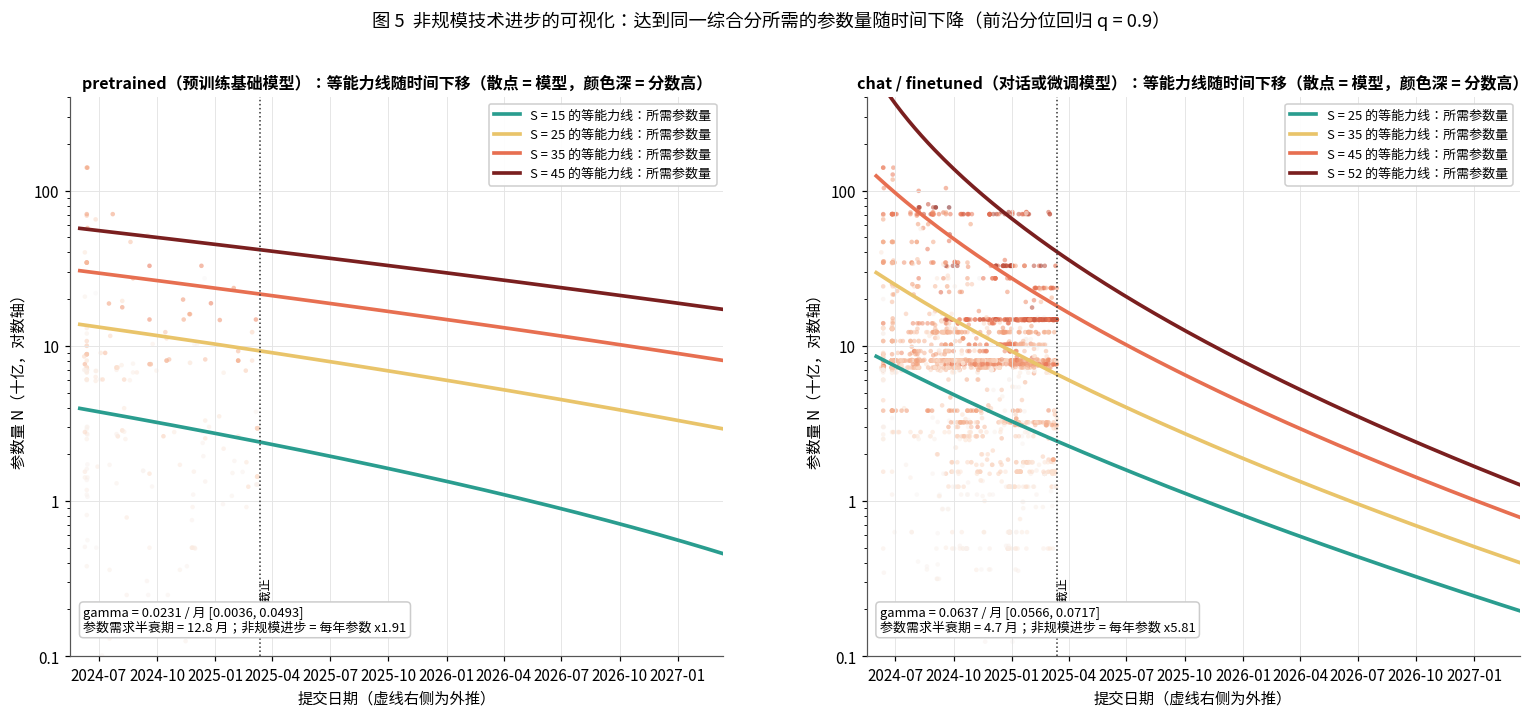

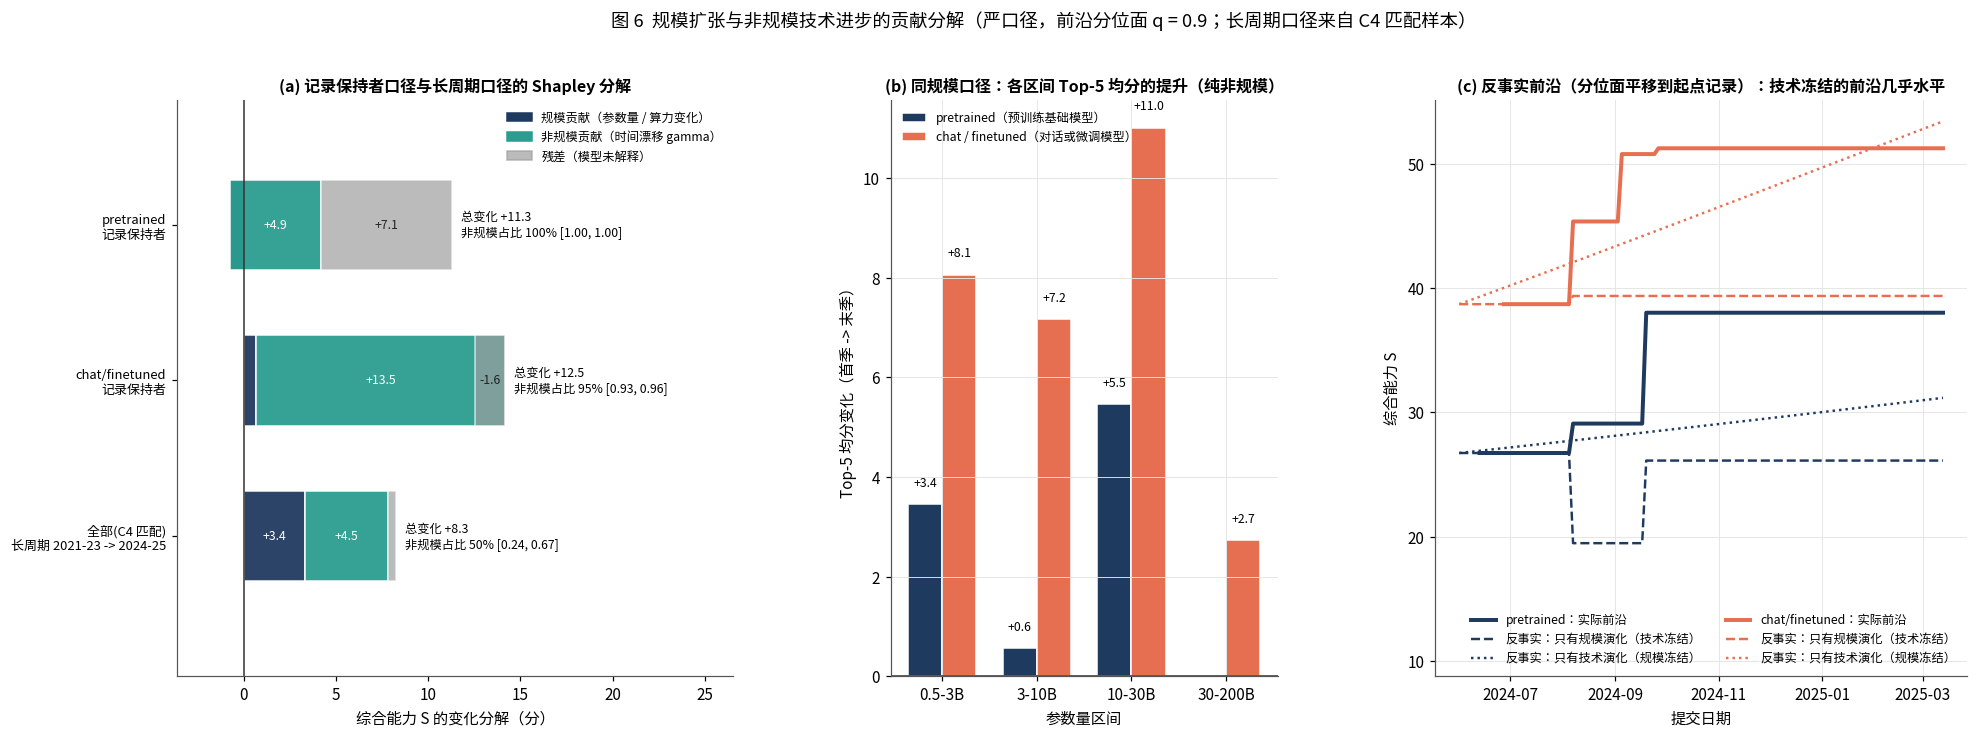

In [4]:
# ============ 3. 能力生产函数、分位数回归与分解 ============
def quantreg(X, y, q=0.9):
    """分位数回归（线性规划）：min q*sum(u) + (1-q)*sum(v)  s.t.  X b + u - v = y"""
    n, p = X.shape; c = np.r_[np.zeros(p), q * np.ones(n), (1 - q) * np.ones(n)]
    A = np.hstack([X, np.eye(n), -np.eye(n)]); bounds = [(None, None)] * p + [(0, None)] * (2 * n)
    r = linprog(c, A_eq=A, b_eq=y, bounds=bounds, method='highs'); return r.x[:p]
def design(lnN, tau_): return np.column_stack([np.ones(len(lnN)), lnN, lnN ** 2, tau_])
def f_pred(b, N, tau_): lnN = np.log(np.asarray(N, float)); return 100 * expit(b[0] + b[1] * lnN + b[2] * lnN ** 2 + b[3] * np.asarray(tau_, float))

Q_FRONT = 0.9; FIT = {}; BOOT = {}
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]; X = design(d['lnN'].values, d['tau'].values); yv = d['y'].values
    b = quantreg(X, yv, Q_FRONT); bo = np.array([quantreg(X[idx], yv[idx], Q_FRONT) for idx in (RNG.integers(0, len(d), len(d)) for _ in range(150))])
    ols, *_ = np.linalg.lstsq(X, yv, rcond=None); FIT[g] = {'b': b, 'ols': ols, 'n': len(d), 'corr_lnN_tau': float(np.corrcoef(d['lnN'], d['tau'])[0, 1])}; BOOT[g] = bo
    Nref = float(np.exp(np.median(d['lnN']))); bN = b[1] + 2 * b[2] * np.log(Nref); bN_bo = bo[:, 1] + 2 * bo[:, 2] * np.log(Nref)
    FIT[g].update({'N_ref': Nref, 'beta_N': bN, 'gamma': b[3], 'half_life_month': np.log(2) * bN / b[3] if b[3] > 0 else np.inf, 'annual_param_multiplier': float(np.exp(12 * b[3] / bN)),
                   'gamma_ci': np.percentile(bo[:, 3], [2.5, 97.5]).tolist(), 'mult_ci': np.percentile(np.exp(12 * bo[:, 3] / bN_bo), [2.5, 97.5]).tolist()})
    print('%s（严口径 n=%d，corr(lnN, tau)=%.2f）: 前沿分位回归 q=%.1f: b1=%.3f b2=%.4f gamma=%.4f/月 [95%% CI %.4f, %.4f]; 参考规模 %.0fB 处 beta_N=%.3f -> 参数需求半衰期 %.1f 月, 非规模进步 = 每年参数 x%.2f [%.2f, %.2f]; OLS gamma=%.4f'
          % (g, len(d), FIT[g]['corr_lnN_tau'], Q_FRONT, b[1], b[2], b[3], *FIT[g]['gamma_ci'], Nref / 1e9, bN, FIT[g]['half_life_month'], FIT[g]['annual_param_multiplier'], *FIT[g]['mult_ci'], ols[3]))

# 参数需求半衰期与年等价参数倍数在不同参考规模处的取值（beta_N 随规模变化）
rows = []
for g in FIT:
    b = FIT[g]['b']
    for Nr in (1e9, 8e9, 70e9):
        bN = b[1] + 2 * b[2] * np.log(Nr); rows.append({'类型': g, '参考规模': '%gB' % (Nr / 1e9), 'beta_N': bN, '参数需求半衰期(月)': np.log(2) * bN / b[3] if b[3] > 0 and bN > 0 else np.inf, '年等价参数倍数': float(np.exp(12 * b[3] / bN)) if bN > 0 else np.nan})
HL = pd.DataFrame(rows); print('\n不同参考规模处的半衰期与年等价参数倍数:'); display(HL); HL.to_csv(TAB / 'half_life_by_scale.csv', index=False, encoding='utf-8-sig')

# Shapley 分解（三种口径）
def shapley(b, N0, t0, N1, t1):
    f = lambda N, t: float(f_pred(b, [N], [t])[0])
    scale = 0.5 * ((f(N1, t0) - f(N0, t0)) + (f(N1, t1) - f(N0, t1))); tech = 0.5 * ((f(N0, t1) - f(N0, t0)) + (f(N1, t1) - f(N1, t0)))
    return scale, tech, f(N0, t0), f(N1, t1)
def top_group(df, lo, hi, q=0.9):
    d = df[(df['tau'] >= lo) & (df['tau'] < hi)]; thr = d['S'].quantile(q); top = d[d['S'] >= thr]; return float(np.exp(top['lnN'].median())), float(top['tau'].mean()), float(top['S'].mean()), len(top)
DEC = []
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]; e = ENV[g]
    # (i) 记录保持者口径
    N0, t0, N1, t1 = e['N_B'].iloc[0] * 1e9, e['tau'].iloc[0], e['N_B'].iloc[-1] * 1e9, float(LB['tau'].max())
    sc, te, f0, f1 = shapley(FIT[g]['b'], N0, t0, N1, t1); dF = e['S'].iloc[-1] - e['S'].iloc[0]; bo = np.array([shapley(bb, N0, t0, N1, t1)[:2] for bb in BOOT[g]])
    DEC.append({'类型': g, '口径': '记录保持者', '起点': '%s (%.0fB, %.1f)' % (e['Model'].iloc[0].split('/')[-1][:22], N0 / 1e9, e['S'].iloc[0]), '终点': '%s (%.0fB, %.1f)' % (e['Model'].iloc[-1].split('/')[-1][:22], N1 / 1e9, e['S'].iloc[-1]), 'S0': e['S'].iloc[0], 'S1': e['S'].iloc[-1],
                '实际变化': dF, '规模贡献': sc, '非规模贡献': te, '残差': dF - (sc + te), '非规模占比': np.clip(te / (sc + te), 0, 1) if (sc + te) > 0 else np.nan, '占比 95% CI': '[%.2f, %.2f]' % tuple(np.clip(np.percentile(bo[:, 1] / (bo[:, 0] + bo[:, 1]), [2.5, 97.5]), 0, 1))})
DECDF = pd.DataFrame(DEC); print('\nShapley 分解（严口径，q=0.9 前沿面；占比截断到 [0,1]，规模贡献为负时非规模占比记为 100%）:'); display(DECDF)
# (ii) 同规模口径（无模型）：各参数量区间内 Top-5 均分从首季到末季的变化，全部是非规模进步
BANDS = [(0.5, 3, '0.5-3B'), (3, 10, '3-10B'), (10, 30, '10-30B'), (30, 200, '30-200B')]; rows = []
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]
    for lo, hi, lab in BANDS:
        e0 = d[(d['N_B'] >= lo) & (d['N_B'] < hi) & (d['tau'] < 3)]['S'].nlargest(5); e1 = d[(d['N_B'] >= lo) & (d['N_B'] < hi) & (d['tau'] >= LB['tau'].max() - 3)]['S'].nlargest(5)
        rows.append({'类型': g, '规模区间': lab, '首季 Top-5 均分': e0.mean(), '末季 Top-5 均分': e1.mean(), '同规模增益': e1.mean() - e0.mean(), 'n 首季/末季': '%d/%d' % (len(e0), len(e1))})
BAND = pd.DataFrame(rows); print('\n同规模口径：各参数量区间内 Top-5 均分的首季 -> 末季变化（纯非规模进步）:'); display(BAND); BAND.to_csv(TAB / 'same_scale_gains.csv', index=False, encoding='utf-8-sig')

# 以算力为规模变量的补充分解（C1 x C4 名称匹配）
def norm_name(s):
    s = str(s).lower().split('/')[-1]; s = re.sub(r'[\s_\-\.]', '', s); return s.replace('instruct', 'it').replace('chat', '')
C4L = C4[C4['Domain'].astype(str).str.contains('Language')].copy(); C4L['key'] = C4L['Model'].map(norm_name); C4L['C'] = pd.to_numeric(C4L['Training compute (FLOP)'], errors='coerce'); C4L['date_pub4'] = pd.to_datetime(C4L['Publication date'], errors='coerce')
C4L['D_tokens'] = pd.to_numeric(C4L['Training dataset size (total)'], errors='coerce'); C4L['open_w'] = C4L['Open model weights?']
LB['key'] = LB['Model'].map(norm_name); MC = LB.merge(C4L.dropna(subset=['C']).drop_duplicates('key')[['key', 'C', 'date_pub4', 'D_tokens', 'open_w', 'Organization']], on='key', how='inner')
MC['tau_pub'] = (MC['date_pub4'] - T0).dt.days / 30.4375; MC = MC.dropna(subset=['tau_pub'])
print('\n与 Epoch AI 训练算力匹配的排行榜模型: %d 个（pretrained %d, chat %d），发布日期 %s 至 %s' % (len(MC), (MC['type'] == 'pretrained').sum(), (MC['type'] == 'chat/finetuned').sum(), MC['date_pub4'].min().date(), MC['date_pub4'].max().date()))
Xc = np.column_stack([np.ones(len(MC)), np.log(MC['C']), MC['tau_pub'], (MC['type'] == 'chat/finetuned').astype(float)]); yc = MC['y'].values
bc, *_ = np.linalg.lstsq(Xc, yc, rcond=None); bo_c = np.array([np.linalg.lstsq(Xc[idx], yc[idx], rcond=None)[0] for idx in (RNG.integers(0, len(MC), len(MC)) for _ in range(300))])
mult_C = np.exp(12 * bc[2] / bc[1]); mult_C_ci = np.percentile(np.exp(12 * bo_c[:, 2] / bo_c[:, 1]), [2.5, 97.5])
R2c = 1 - ((yc - Xc @ bc) ** 2).sum() / ((yc - yc.mean()) ** 2).sum()
print('  logit(S) = %.2f + %.3f ln C + %.4f tau_pub + %.3f chat  (R2 = %.3f)' % (bc[0], bc[1], bc[2], bc[3], R2c))
print('  -> 有效算力年增倍数 exp(12 gamma_C / beta_C) = x%.2f [95%% CI %.2f, %.2f]（算法/数据工程进步的算力等价物，2021-2025 长周期）' % (mult_C, *mult_C_ci))
a_exp = Q2['compute_optimal']['a']; print('  对照：参数量口径的年增倍数 x%.2f（pretrained, 2024-25 短周期），按 N* ~ C^%.2f 折算为算力倍数 x%.2f' % (FIT['pretrained']['annual_param_multiplier'], a_exp, FIT['pretrained']['annual_param_multiplier'] ** (1 / a_exp)))
ALG = {'mult_C_epoch': float(mult_C), 'mult_C_ci': mult_C_ci.tolist(), 'mult_N_pre': FIT['pretrained']['annual_param_multiplier'], 'mult_N_chat': FIT['chat/finetuned']['annual_param_multiplier'], 'a_exp': float(a_exp)}
# (iii) 长周期口径：C4 匹配样本中，2021-2023 发布的模型 vs 2024-2025 发布的模型，平均 logit 能力之差按 beta_C dlnC + gamma_C dtau 分解（控制 chat 构成）
early_ = MC[MC['date_pub4'] < '2024-01-01']; late_ = MC[MC['date_pub4'] >= '2024-01-01']
dy_ = late_['y'].mean() - early_['y'].mean(); dC_ = np.log(late_['C']).mean() - np.log(early_['C']).mean(); dt_ = late_['tau_pub'].mean() - early_['tau_pub'].mean(); dchat_ = (late_['type'] == 'chat/finetuned').mean() - (early_['type'] == 'chat/finetuned').mean()
sc_C, te_C, ch_C = bc[1] * dC_, bc[2] * dt_, bc[3] * dchat_; bo_sh = (bo_c[:, 2] * dt_) / (bo_c[:, 1] * dC_ + bo_c[:, 2] * dt_)
print('长周期分解（C4 匹配样本 %d vs %d 个模型）: 平均 logit 能力上升 %.2f；算力增长 x%.0f (dlnC=%.2f) 贡献 %.2f，时间 %.0f 个月的技术进步贡献 %.2f，类型构成 %.2f，残差 %.2f -> 非规模占比 %.0f%% [95%% CI %.0f%%, %.0f%%]'
      % (len(early_), len(late_), dy_, np.exp(dC_), dC_, sc_C, dt_, te_C, ch_C, dy_ - sc_C - te_C - ch_C, 100 * te_C / (sc_C + te_C), *(100 * np.clip(np.percentile(bo_sh, [2.5, 97.5]), 0, 1))))
DECDF = pd.concat([DECDF, pd.DataFrame([{'类型': '全部(C4 匹配)', '口径': '长周期 2021-23 -> 2024-25', '起点': '%d 个模型, 均 logit %.2f' % (len(early_), early_['y'].mean()), '终点': '%d 个模型, 均 logit %.2f' % (len(late_), late_['y'].mean()), 'S0': 100 * expit(early_['y'].mean()), 'S1': 100 * expit(late_['y'].mean()),
    '实际变化': 100 * expit(late_['y'].mean()) - 100 * expit(early_['y'].mean()), '规模贡献': 100 * (expit(early_['y'].mean() + sc_C) - expit(early_['y'].mean())), '非规模贡献': 100 * (expit(early_['y'].mean() + sc_C + te_C) - expit(early_['y'].mean() + sc_C)), '残差': 100 * (expit(late_['y'].mean()) - expit(early_['y'].mean() + sc_C + te_C)), '非规模占比': float(np.clip(te_C / (sc_C + te_C), 0, 1)), '占比 95% CI': '[%.2f, %.2f]' % tuple(np.clip(np.percentile(bo_sh, [2.5, 97.5]), 0, 1))}])], ignore_index=True)
DECDF.to_csv(TAB / 'shapley_decomposition.csv', index=False, encoding='utf-8-sig')
json.dump({'quantile_fits': {g: {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in FIT[g].items()} for g in FIT}, 'compute_based': {'coef': bc.tolist(), 'R2': float(R2c), **ALG}}, open(TAB / 'production_function_fits.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)
MC.to_csv(TAB / 'leaderboard_matched_epoch_compute.csv', index=False, encoding='utf-8-sig')

# ---- 图 5：等能力线的左移（达到同一分数所需参数量随时间下降）+ 参数需求半衰期 ----
fig = plt.figure(figsize=(17, 6.6)); gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1], wspace=0.22)
tt = np.linspace(0, LB['tau'].max() + 24, 200); dates = [T0 + pd.Timedelta(days=30.4375 * v) for v in tt]
for ax, g in zip((fig.add_subplot(gs[0]), fig.add_subplot(gs[1])), ('pretrained', 'chat/finetuned')):
    d = LB[(LB['type'] == g) & LB['open_strict']]; b = FIT[g]['b']
    ax.scatter(d['date_sub'], d['N_B'], s=9, c=d['S'], cmap=CMAP_HEAT, alpha=0.55, edgecolor='none', vmin=0, vmax=52)
    levels = [15, 25, 35, 45] if g == 'pretrained' else [25, 35, 45, 52]
    for lv, c in zip(levels, [C_TEAL, C_GOLD, C_CORAL, C_RUST]):
        ylv = logit(lv / 100); Nreq = []
        for t_ in tt:                                             # 解 b0 + b1 x + b2 x^2 + gamma t = ylv 的 x（取物理解）
            A2, B2, C2_ = b[2], b[1], b[0] + b[3] * t_ - ylv; disc = B2 ** 2 - 4 * A2 * C2_
            if abs(A2) < 1e-9: x = -C2_ / B2
            else:
                if disc < 0: Nreq.append(np.nan); continue
                x1, x2 = (-B2 - np.sqrt(disc)) / (2 * A2), (-B2 + np.sqrt(disc)) / (2 * A2); x = min([v for v in (x1, x2) if 15 < v < 30], default=np.nan)
            Nreq.append(np.exp(x) / 1e9 if np.isfinite(x) else np.nan)
        ax.plot(dates, Nreq, color=c, lw=2.4, label='S = %d 的等能力线：所需参数量' % lv)
    ax.axvline(LB['date_sub'].max(), color='#333333', lw=1, ls=':'); ax.text(LB['date_sub'].max(), 0.15, ' 数据截止 ', fontsize=8, rotation=90, va='bottom')
    ax.set_yscale('log'); ax.yaxis.set_major_formatter(plain); ax.set_ylim(0.1, 400); ax.set_xlim(T0 - pd.Timedelta(days=15), dates[-1]); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m'))
    ax.set_xlabel('提交日期（虚线右侧为外推）'); ax.set_ylabel('参数量 N（十亿，对数轴）'); ax.legend(frameon=True, fontsize=8.5, loc='upper right', facecolor='white', framealpha=0.95)
    ax.text(0.02, 0.04, 'gamma = %.4f / 月 [%.4f, %.4f]\n参数需求半衰期 = %.1f 月；非规模进步 = 每年参数 x%.2f' % (FIT[g]['gamma'], *FIT[g]['gamma_ci'], FIT[g]['half_life_month'], FIT[g]['annual_param_multiplier']), transform=ax.transAxes, fontsize=8.5, va='bottom', bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
    ax.set_title('%s：等能力线随时间下移（散点 = 模型，颜色深 = 分数高）' % NAME_TYPE[g], fontsize=10.5)
fig.suptitle('图 5  非规模技术进步的可视化：达到同一综合分所需的参数量随时间下降（前沿分位回归 q = 0.9）', fontsize=12, y=1.0)
savefig('fig05_isoability_requirement_curves.png'); plt.show()

# ---- 图 6：三种口径的贡献分解（分段条）+ 反事实前沿 ----
fig = plt.figure(figsize=(21, 6.8)); gs = gridspec.GridSpec(1, 3, width_ratios=[1.15, 0.8, 1.1], wspace=0.32)
ax = fig.add_subplot(gs[0]); ax.grid(False); ylabels = []
for k, r in DECDF.iloc[::-1].reset_index(drop=True).iterrows():
    tot = r['实际变化']; parts = [('规模', r['规模贡献'], C_NAVY), ('非规模', r['非规模贡献'], C_TEAL), ('残差', r['残差'], C_GREY)]; left = 0.0; right_edge = 0.0
    for name, val, col in parts:
        ax.barh(k, val, left=left, height=0.58, color=col, edgecolor='white', alpha=0.95 if name != '残差' else 0.7)
        if abs(val) > 0.8: ax.text(left + val / 2, k, '%+.1f' % val, ha='center', va='center', fontsize=8, color='white' if name != '残差' else '#222222')
        left += val; right_edge = max(right_edge, left)
    ax.text(right_edge + 0.5, k, '总变化 %+.1f\n非规模占比 %.0f%% %s' % (tot, 100 * r['非规模占比'], r['占比 95% CI']), va='center', fontsize=8)
    ylabels.append('%s\n%s' % (r['类型'], r['口径']))
ax.set_yticks(range(len(DECDF))); ax.set_yticklabels(ylabels, fontsize=8.5); ax.axvline(0, color='#333333', lw=1); ax.set_xlim(min(0, DECDF[['规模贡献', '非规模贡献', '残差']].min().min() - 2), DECDF['实际变化'].max() + 14); ax.set_ylim(-0.9, len(DECDF) - 0.2)
ax.set_xlabel('综合能力 S 的变化分解（分）'); ax.legend(handles=[Patch(color=C_NAVY, label='规模贡献（参数量 / 算力变化）'), Patch(color=C_TEAL, label='非规模贡献（时间漂移 gamma）'), Patch(color=C_GREY, alpha=0.7, label='残差（模型未解释）')], frameon=False, fontsize=8, loc='upper right')
ax.set_title('(a) 记录保持者口径与长周期口径的 Shapley 分解', fontsize=10.5)
ax = fig.add_subplot(gs[1]); xb = np.arange(len(BANDS)); wb = 0.36
for k_, g in enumerate(('pretrained', 'chat/finetuned')):
    d = BAND[BAND['类型'] == g]; ax.bar(xb + (k_ - 0.5) * wb, d['同规模增益'], wb, color=COL_TYPE[g], edgecolor='white', label=NAME_TYPE[g])
    for x_, v, n_ in zip(xb + (k_ - 0.5) * wb, d['同规模增益'], d['n 首季/末季']): ax.text(x_, v + (0.3 if v >= 0 else -0.3), '%+.1f' % v, ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)
ax.axhline(0, color='#333333', lw=1); ax.set_xticks(xb); ax.set_xticklabels([b_[2] for b_ in BANDS]); ax.set_xlabel('参数量区间'); ax.set_ylabel('Top-5 均分变化（首季 -> 末季）'); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_title('(b) 同规模口径：各区间 Top-5 均分的提升（纯非规模）', fontsize=10.5)
ax = fig.add_subplot(gs[2]); tgrid = np.linspace(0, LB['tau'].max(), 120); dgrid = [T0 + pd.Timedelta(days=30.4375 * v) for v in tgrid]
for g in ('pretrained', 'chat/finetuned'):
    e = ENV[g]; b = FIT[g]['b']; c = COL_TYPE[g]
    Nenv = np.array([e.loc[e['tau'] <= t_, 'N_B'].iloc[-1] if (e['tau'] <= t_).any() else e['N_B'].iloc[0] for t_ in tgrid]) * 1e9
    Fact = np.array([e.loc[e['tau'] <= t_, 'S'].iloc[-1] if (e['tau'] <= t_).any() else np.nan for t_ in tgrid])
    shift = logit(e['S'].iloc[0] / 100) - logit(f_pred(b, [Nenv[0]], [tgrid[0]])[0] / 100)           # 把分位面平移到起点记录，便于对照
    fcf = lambda N, t: 100 * expit(logit(f_pred(b, N, t) / 100) + shift)
    ax.plot(dgrid, Fact, color=c, lw=2.6, label='%s：实际前沿' % g); ax.plot(dgrid, fcf(Nenv, np.full_like(tgrid, tgrid[0])), color=c, lw=1.6, ls='--', label='反事实：只有规模演化（技术冻结）')
    ax.plot(dgrid, fcf(np.full_like(tgrid, Nenv[0]), tgrid), color=c, lw=1.6, ls=':', label='反事实：只有技术演化（规模冻结）')
ax.xaxis.set_major_locator(mpl.dates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m')); ax.set_ylabel('综合能力 S'); ax.set_xlabel('提交日期'); ax.set_ylim(ax.get_ylim()[0] - 9, ax.get_ylim()[1]); ax.legend(frameon=False, fontsize=8, ncol=2, loc='lower right')
ax.set_title('(c) 反事实前沿（分位面平移到起点记录）：技术冻结的前沿几乎水平', fontsize=10.5)
fig.suptitle('图 6  规模扩张与非规模技术进步的贡献分解（严口径，前沿分位面 q = 0.9；长周期口径来自 C4 匹配样本）', fontsize=12, y=1.0)
savefig('fig06_shapley_waterfall_counterfactual.png'); plt.show()

## 4. 长周期视角与算力增长情景

### 4.1 C3 的长周期（2019–2025）

C3 把 26 个历史模型（论文/报告估算，评测标准不完全一致）与排行榜拼接成 2019–2025 的时序。它不能与 C1 做同精度的回归，但足以给出"时代"的定性对照：2019–2022 的前沿由 GPT-3 / Chinchilla / OPT 这类 **百亿到千亿参数** 的规模跃迁推动；2023 之后 LLaMA、Mistral、Qwen 系列在 **7B–70B** 的规模上持续刷新前沿——同一规模区间内的分数上升就是非规模进步。

### 4.2 C4 的开源前沿训练算力与"放缓"情景

用 C4 中 `Domain` 含 Language、`Open model weights? = Yes` 且有训练算力的模型，按发布日期做 $\log_{10}C$ 的分位数回归（$q=0.9$，"前沿算力"），分 2019–2023 与 2023 之后两段估计年增长率。赛题要求在 **算力增长放缓** 情景下预测，本文设三档情景（年增倍数 $G_{phys}$）：
* **延续**：最近一段（2023 年至数据末）的拟合增长率；
* **放缓**：对数增长率减半；
* **停滞**：$G_{phys}=1$（前沿算力不再增长，只有非规模进步）。

C3 各年最高分与累计记录（仅开源权重模型；GPT-3 与 Chinchilla 为闭源，剔除）:
2019-2023 前半段: n=136, 前沿(q=0.9)算力年增 x2.92 [1.94, 3.34]（log10 斜率 0.465/年）, 中位年增 x2.98
2023.5 至数据末: n=351, 前沿(q=0.9)算力年增 x2.67 [2.18, 4.45]（log10 斜率 0.427/年）, 中位年增 x5.45
算力增长情景（年增倍数 G_phys）: {'延续（最近段拟合）': np.float64(2.67), '放缓（对数增长率减半）': 1.63, '停滞（前沿算力不增长）': 1.0}
数据截止 2025-03-13 前开源 LM 的最大训练算力: 3.80e+25 (Llama 3.1-405B)；排行榜前沿基座 Qwen2.5-72B 的训练算力: 7.80e+24
C4 中数据截止之后（2025-03-13 之后）新增开源 LM 94 个，其中最大算力 3.91e+25（Llama Nemotron Ultra 253B）—— 可作为算力情景的事后核对


,Model,Params_B,S3,累计记录
Year,,,,
2019,GPT-2 (1.5B),1.5000,5.0000,5.0000
2021,GPT-J (6B),6.0000,5.0000,5.0000
2022,OPT (175B),175.0000,30.0000,30.0000
2023,LLaMA (65B),65.0000,35.0000,35.0000
2024,MaziyarPanahi/calme-3.2-instruct-78b,77.9650,52.0800,52.0800
2025,fluently-lm/FluentlyLM-Prinum,32.7640,47.2200,52.0800


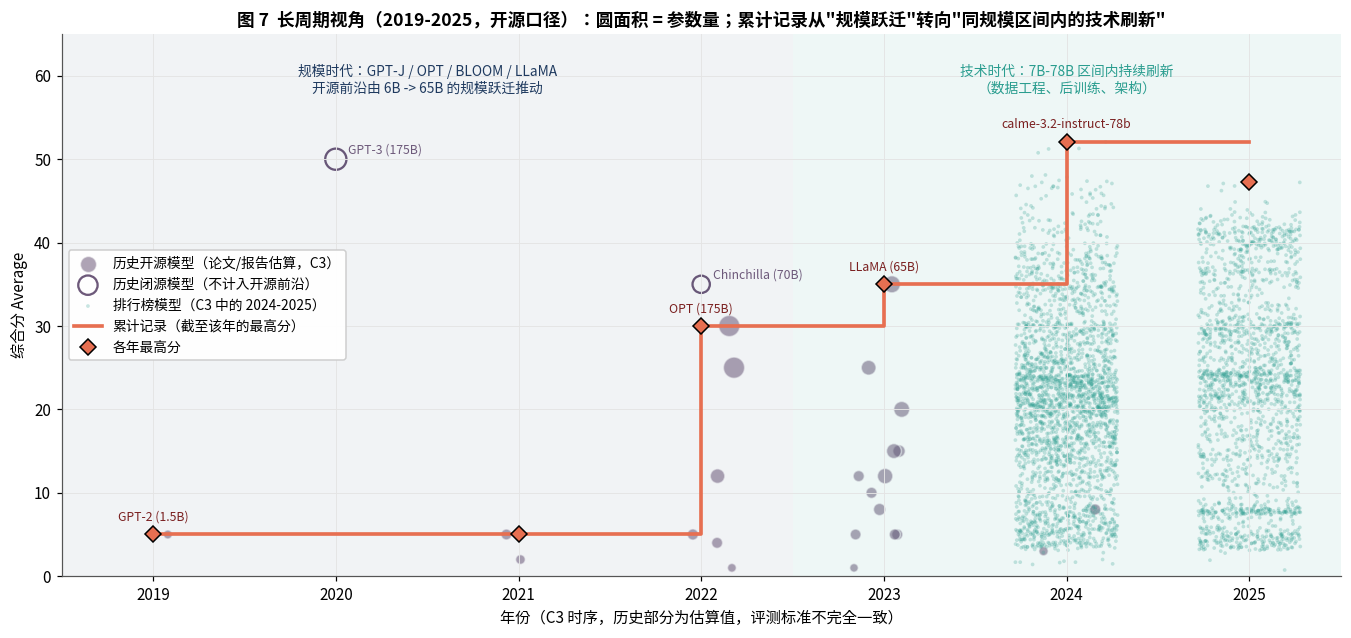

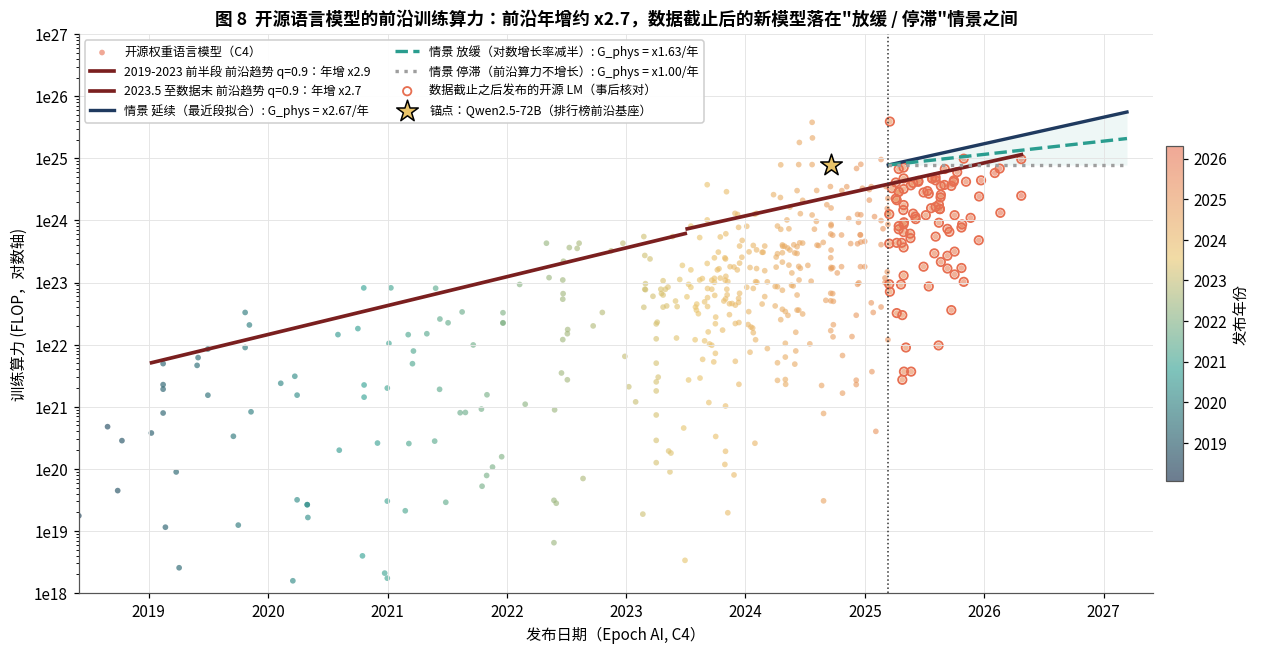

In [5]:
# ============ 4. 长周期视角 + 算力增长情景 ============
C3['is_hist'] = C3['Source'].str.startswith('Historical'); C3['S3'] = C3['Average']
CLOSED_HIST = ('GPT-3', 'Chinchilla')                                   # 历史模型中未开源权重者（不计入开源前沿）
C3['is_open'] = ~(C3['is_hist'] & C3['Model'].str.startswith(CLOSED_HIST))
C3o = C3[C3['is_open']]; yr_max = C3o.groupby('Year').apply(lambda d: d.loc[d['S3'].idxmax()])[['Model', 'Params_B', 'S3']]; yr_front = yr_max.copy(); yr_front['S3'] = yr_max['S3'].cummax()
for y_ in yr_front.index:                                   # 累计记录的保持者
    hold = yr_max[yr_max['S3'] == yr_front.loc[y_, 'S3']].index.min(); yr_front.loc[y_, ['Model', 'Params_B']] = yr_max.loc[hold, ['Model', 'Params_B']]
print('C3 各年最高分与累计记录（仅开源权重模型；GPT-3 与 Chinchilla 为闭源，剔除）:'); display(yr_max.join(yr_front[['S3']].rename(columns={'S3': '累计记录'})))
fig, ax = plt.subplots(figsize=(15, 6.4))
h = C3[C3.is_hist & C3.is_open]; ax.scatter(h['Year'] + RNG.uniform(-0.18, 0.18, len(h)), h['S3'], s=18 + 2.2 * np.sqrt(h['Params_B']) * 6, color=C_PLUM, alpha=0.55, edgecolor='white', label='历史开源模型（论文/报告估算，C3）')
hc = C3[C3.is_hist & ~C3.is_open]; ax.scatter(hc['Year'], hc['S3'], s=18 + 2.2 * np.sqrt(hc['Params_B']) * 6, facecolors='none', edgecolors=C_PLUM, linewidths=1.5, label='历史闭源模型（不计入开源前沿）')
for _, r in hc.iterrows(): ax.annotate(r['Model'], (r['Year'], r['S3']), xytext=(8, 4), textcoords='offset points', fontsize=8, color=C_PLUM)
lb3 = C3[~C3.is_hist]; ax.scatter(lb3['Year'] + RNG.uniform(-0.28, 0.28, len(lb3)), lb3['S3'], s=6, color=C_TEAL, alpha=0.25, edgecolor='none', label='排行榜模型（C3 中的 2024-2025）')
ax.step(yr_front.index, yr_front['S3'], where='post', color=C_CORAL, lw=2.4, label='累计记录（截至该年的最高分）'); ax.plot(yr_max.index, yr_max['S3'], color=C_CORAL, lw=0, marker='D', ms=7, mec='black', label='各年最高分')
last = None
for y_, r in yr_front.iterrows():
    if r['Model'] != last: ax.annotate('%s' % r['Model'].split('/')[-1][:24], (y_, r['S3']), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=8, color=C_RUST); last = r['Model']
ax.axvspan(2018.5, 2022.5, color=C_NAVY, alpha=0.06, lw=0); ax.axvspan(2022.5, 2025.5, color=C_TEAL, alpha=0.08, lw=0)
ax.text(2020.5, 58, '规模时代：GPT-J / OPT / BLOOM / LLaMA\n开源前沿由 6B -> 65B 的规模跃迁推动', ha='center', fontsize=9, color=C_NAVY); ax.text(2024, 58, '技术时代：7B-78B 区间内持续刷新\n（数据工程、后训练、架构）', ha='center', fontsize=9, color=C_TEAL)
ax.set_xlim(2018.5, 2025.5); ax.set_ylim(0, 65); ax.set_xlabel('年份（C3 时序，历史部分为估算值，评测标准不完全一致）'); ax.set_ylabel('综合分 Average'); ax.legend(frameon=True, fontsize=9, loc='center left', facecolor='white', framealpha=0.95)
ax.set_title('图 7  长周期视角（2019-2025，开源口径）：圆面积 = 参数量；累计记录从"规模跃迁"转向"同规模区间内的技术刷新"', fontsize=11.5)
savefig('fig07_long_horizon_eras.png'); plt.show()

# C4：开源语言模型的前沿训练算力
OW = C4L.dropna(subset=['C', 'date_pub4']); OW = OW[(OW['open_w'] == 'Yes') & (OW['date_pub4'] >= '2018-01-01')].copy(); OW['yr'] = OW['date_pub4'].dt.year + OW['date_pub4'].dt.dayofyear / 365.25; OW['log10C'] = np.log10(OW['C'])
seg = {'2019-2023 前半段': OW[(OW['yr'] >= 2019) & (OW['yr'] < 2023.5)], '2023.5 至数据末': OW[OW['yr'] >= 2023.5]}; GR = {}
for name, d in seg.items():
    X = np.column_stack([np.ones(len(d)), d['yr'] - 2020]); b9 = quantreg(X, d['log10C'].values, 0.9); bmed = quantreg(X, d['log10C'].values, 0.5)
    bo = np.array([quantreg(X[idx], d['log10C'].values[idx], 0.9)[1] for idx in (RNG.integers(0, len(d), len(d)) for _ in range(200))])
    GR[name] = {'n': len(d), 'slope_q90': b9[1], 'mult_q90': 10 ** b9[1], 'ci_mult': (10 ** np.percentile(bo, [2.5, 97.5])).tolist(), 'slope_q50': bmed[1], 'b9': b9}
    print('%s: n=%d, 前沿(q=0.9)算力年增 x%.2f [%.2f, %.2f]（log10 斜率 %.3f/年）, 中位年增 x%.2f' % (name, len(d), 10 ** b9[1], *GR[name]['ci_mult'], b9[1], 10 ** bmed[1]))
G_RECENT = GR['2023.5 至数据末']['mult_q90']; SCEN = {'延续（最近段拟合）': G_RECENT, '放缓（对数增长率减半）': float(np.sqrt(G_RECENT)), '停滞（前沿算力不增长）': 1.0}
print('算力增长情景（年增倍数 G_phys）:', {k: round(v, 2) for k, v in SCEN.items()})
last_date = LB['date_sub'].max(); anchor = OW[OW['date_pub4'] <= last_date].sort_values('C', ascending=False).head(5)
C_ANCHOR_MAX = float(anchor['C'].iloc[0]); q_row = C4L[C4L['key'] == norm_name('Qwen/Qwen2.5-72B')]; C_ANCHOR_LB = float(q_row['C'].iloc[0]) if len(q_row) else np.nan
print('数据截止 %s 前开源 LM 的最大训练算力: %.2e (%s)；排行榜前沿基座 Qwen2.5-72B 的训练算力: %.2e' % (last_date.date(), C_ANCHOR_MAX, anchor['Model'].iloc[0], C_ANCHOR_LB))
after = OW[OW['date_pub4'] > last_date]; print('C4 中数据截止之后（%s 之后）新增开源 LM %d 个，其中最大算力 %.2e（%s）—— 可作为算力情景的事后核对' % (last_date.date(), len(after), after['C'].max(), after.loc[after['C'].idxmax(), 'Model']))
pd.DataFrame([{'段': k, **{kk: vv for kk, vv in v.items() if kk != 'b9'}} for k, v in GR.items()]).to_csv(TAB / 'compute_growth_fits.csv', index=False, encoding='utf-8-sig')

# ---- 图 8：开源 LM 前沿算力与情景锥 ----
fig, ax = plt.subplots(figsize=(15, 6.6))
sc = ax.scatter(OW['date_pub4'], OW['C'], s=14, c=OW['yr'], cmap=CMAP_TIME, alpha=0.6, edgecolor='none', label='开源权重语言模型（C4）')
for name, v in GR.items():
    d = seg[name]; xs = np.linspace(d['yr'].min(), d['yr'].max(), 50); ys = 10 ** (v['b9'][0] + v['b9'][1] * (xs - 2020)); ax.plot([pd.Timestamp('2020-01-01') + pd.Timedelta(days=365.25 * (x - 2020)) for x in xs], ys, color=C_RUST, lw=2.4, label='%s 前沿趋势 q=0.9：年增 x%.1f' % (name, v['mult_q90']))
t_end = last_date; hs = np.linspace(0, 24, 25)
for (name, G), c, ls in zip(SCEN.items(), [C_NAVY, C_TEAL, C_GREY], ['-', '--', ':']):
    ys = C_ANCHOR_LB * G ** (hs / 12); ax.plot([t_end + pd.Timedelta(days=30.4375 * h_) for h_ in hs], ys, color=c, lw=2.2, ls=ls, label='情景 %s: G_phys = x%.2f/年' % (name, G))
ax.fill_between([t_end + pd.Timedelta(days=30.4375 * h_) for h_ in hs], C_ANCHOR_LB * 1.0 ** (hs / 12), C_ANCHOR_LB * G_RECENT ** (hs / 12), color=C_TEAL, alpha=0.08, lw=0)
ax.scatter(after['date_pub4'], after['C'], s=30, facecolors='none', edgecolors=C_CORAL, linewidths=1.2, label='数据截止之后发布的开源 LM（事后核对）')
ax.axvline(t_end, color='#333333', lw=1, ls=':'); ax.scatter([pd.Timestamp('2024-09-19')], [C_ANCHOR_LB], marker='*', s=220, color=C_GOLD, edgecolor='black', zorder=6, label='锚点：Qwen2.5-72B（排行榜前沿基座）')
ax.set_yscale('log'); ax.yaxis.set_major_formatter(pow10); ax.set_ylim(1e18, 1e27); ax.set_xlim(pd.Timestamp('2018-06-01'), pd.Timestamp('2027-06-01')); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y'))
ax.set_xlabel('发布日期（Epoch AI, C4）'); ax.set_ylabel('训练算力 (FLOP，对数轴)'); ax.legend(frameon=True, fontsize=8, loc='upper left', facecolor='white', framealpha=0.95, ncol=2)
cb = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.01, format=plain); cb.set_label('发布年份')
ax.set_title('图 8  开源语言模型的前沿训练算力：前沿年增约 x%.1f，数据截止后的新模型落在"放缓 / 停滞"情景之间' % G_RECENT, fontsize=11.5)
savefig('fig08_compute_growth_scenarios.png'); plt.show()

## 5. Loss–Benchmark 桥接：把前三问的"扣分"翻译成"考试得分"

C6 有 75 个模型同时具备验证损失与 6 维 Benchmark：7 个 **高可比**（Pythia，与附件 B 同一验证集）与 68 个 **中可比**（损失来自各技术报告、验证集不同）。综合分是有界量，损失越低分数越高且趋于饱和，因此采用 logistic 桥接
$$S=100\cdot\sigma\big(a+b\,(L_0-L)+c\cdot\mathbb 1[\text{chat}]\big),\qquad L_0=2.5,$$
$c$ 捕捉后训练（指令微调）在同一预训练损失下带来的分数抬升——它本身就是"非规模进步"的一部分。按可比性加权（高可比权重 1、中可比权重 0.5）做加权非线性最小二乘，分层报告残差标准差 $\sigma_{high},\sigma_{med}$；Bootstrap 给出参数分布，用于第 6 节的误差传播。与线性映射比较 AIC 说明形式选择。

有了桥接，问题三的最优损失曲线 $L^\star(C)$（计算最优、$Q=1$、$L_{ctx}=4096$）就能翻译成"预算 $C$ 下可达的综合分"：$S^\star(C)=\Phi(L^\star(C))$。这是结构性预测的核心链条。

桥接拟合: S = 100 sigma(-2.493 + 1.628 (2.5 - L) + 0.808 chat); R2 = 0.489; 残差 std: {'中可比': 8.56, '高可比': 2.4}; AIC logistic 324.0 vs 线性 326.6
Bootstrap 95% CI: a [-2.82, -2.22], b [1.25, 2.25], c(chat) [0.51, 1.09]
高可比子集（7 点）: 桥接预测 RMSE = 5.60 分（分数区间 5.1-6.1）

问题三最优损失 -> 综合分（桥接）:
  C = 1.0e+22: L* = 2.155 -> S(pretrained) = 12.7, S(chat) = 24.6
  C = 7.8e+24: L* = 1.855 -> S(pretrained) = 19.1, S(chat) = 34.7
  C = 1.0e+25: L* = 1.848 -> S(pretrained) = 19.3, S(chat) = 34.9
  C = 1.0e+26: L* = 1.801 -> S(pretrained) = 20.5, S(chat) = 36.7


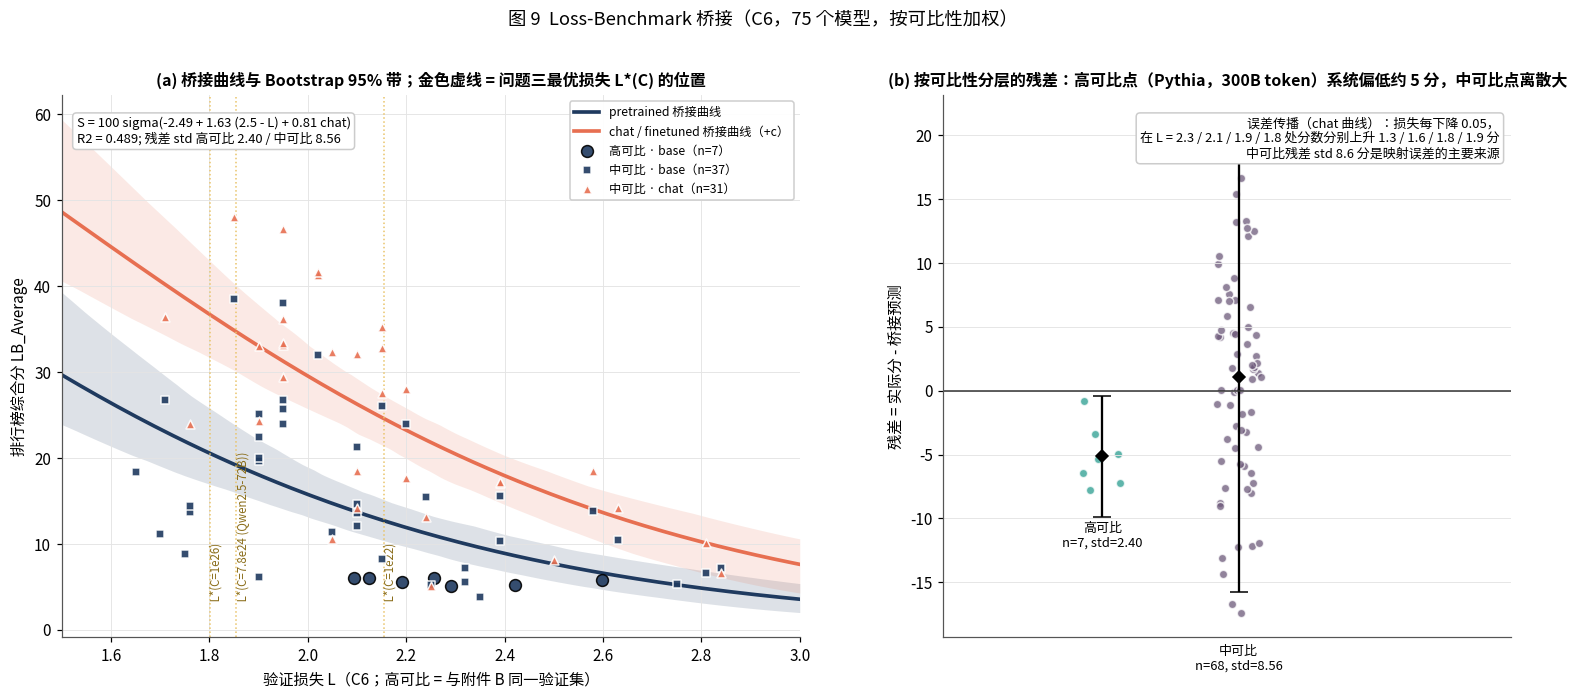

In [6]:
# ============ 5. Loss-Benchmark 桥接 ============
B = C6.copy(); B['chat'] = B['Model'].str.lower().str.contains('instruct|-it$|chat|-it-|orpo|dpo').astype(float); B['w'] = np.where(B['Loss_Comparability'].str.startswith('High'), 1.0, 0.5); B['tier'] = np.where(B['w'] == 1.0, '高可比', '中可比')
L0 = 2.5
def bridge(th, L, chat): return 100 * expit(th[0] + th[1] * (L0 - np.asarray(L, float)) + th[2] * np.asarray(chat, float))
res = least_squares(lambda th: np.sqrt(B['w']) * (bridge(th, B['Val_Loss'], B['chat']) - B['LB_Average']), [-2.0, 3.0, 0.5]); TH_B = res.x
B['pred'] = bridge(TH_B, B['Val_Loss'], B['chat']); B['res'] = B['LB_Average'] - B['pred']
SIG = B.groupby('tier')['res'].std().to_dict(); R2b = 1 - (B['res'] ** 2).sum() / ((B['LB_Average'] - B['LB_Average'].mean()) ** 2).sum()
lin = np.linalg.lstsq(np.column_stack([np.ones(len(B)), B['Val_Loss'], B['chat']]), B['LB_Average'].values, rcond=None)[0]; res_lin = B['LB_Average'] - np.column_stack([np.ones(len(B)), B['Val_Loss'], B['chat']]) @ lin
aic = lambda r, k: len(r) * np.log((r ** 2).mean()) + 2 * k
print('桥接拟合: S = 100 sigma(%.3f + %.3f (2.5 - L) + %.3f chat); R2 = %.3f; 残差 std: %s; AIC logistic %.1f vs 线性 %.1f' % (TH_B[0], TH_B[1], TH_B[2], R2b, {k: round(v, 2) for k, v in SIG.items()}, aic(B['res'].values, 3), aic(res_lin.values, 3)))
BOOT_B = np.array([least_squares(lambda th: np.sqrt(B['w'].values[idx]) * (bridge(th, B['Val_Loss'].values[idx], B['chat'].values[idx]) - B['LB_Average'].values[idx]), TH_B).x for idx in (RNG.integers(0, len(B), len(B)) for _ in range(300))])
print('Bootstrap 95%% CI: a [%.2f, %.2f], b [%.2f, %.2f], c(chat) [%.2f, %.2f]' % tuple(np.percentile(BOOT_B, [2.5, 97.5], axis=0).T.ravel()))
# 高可比子集单独检验（Pythia 7 点）
hi = B[B['w'] == 1.0]; print('高可比子集（%d 点）: 桥接预测 RMSE = %.2f 分（分数区间 %.1f-%.1f）' % (len(hi), np.sqrt((hi['res'] ** 2).mean()), hi['LB_Average'].min(), hi['LB_Average'].max()))
B.to_csv(TAB / 'bridge_fit.csv', index=False, encoding='utf-8-sig'); json.dump({'theta': TH_B.tolist(), 'L0': L0, 'sigma_tier': SIG, 'R2': float(R2b), 'boot': BOOT_B.tolist()}, open(TAB / 'bridge_params.json', 'w', encoding='utf-8'))

# 问题三接口：L*(C) -> S*(C)
LC = Q3['loss_budget_curve_default']; C_curve = np.array(LC['C']); L_curve = np.array(LC['loss_exp']); L_noQ = np.array(LC['loss_noQ'])
def L_star(C): return np.interp(np.log10(C), np.log10(C_curve), L_curve)
def S_star(C, chat, th=None): th = TH_B if th is None else th; return bridge(th, L_star(C), chat)
print('\n问题三最优损失 -> 综合分（桥接）:')
for C in (1e22, 7.8e24, 1e25, 1e26): print('  C = %.1e: L* = %.3f -> S(pretrained) = %.1f, S(chat) = %.1f' % (C, L_star(C), S_star(C, 0), S_star(C, 1)))

# ---- 图 9：桥接曲线（分层）+ 残差与误差传播 ----
fig = plt.figure(figsize=(17, 6.4)); gs = gridspec.GridSpec(1, 2, width_ratios=[1.3, 1], wspace=0.22)
ax = fig.add_subplot(gs[0]); Lg = np.linspace(1.5, 3.0, 200)
for chat_, c, lab in ((0, C_NAVY, 'pretrained 桥接曲线'), (1, C_CORAL, 'chat / finetuned 桥接曲线（+c）')):
    band = np.array([bridge(th, Lg, chat_) for th in BOOT_B]); ax.fill_between(Lg, np.percentile(band, 2.5, axis=0), np.percentile(band, 97.5, axis=0), color=c, alpha=0.15, lw=0)
    ax.plot(Lg, bridge(TH_B, Lg, chat_), color=c, lw=2.4, label=lab)
for (tier, chat_), mk in (( '高可比', 0), 'o'), (('中可比', 0), 's'), (('中可比', 1), '^'):
    d = B[(B['tier'] == tier) & (B['chat'] == chat_)]
    if len(d): ax.scatter(d['Val_Loss'], d['LB_Average'], marker=mk, s=60 if tier == '高可比' else 34, color=C_NAVY if chat_ == 0 else C_CORAL, edgecolor='black' if tier == '高可比' else 'white', linewidths=1, alpha=0.9, zorder=4, label='%s · %s（n=%d）' % (tier, 'chat' if chat_ else 'base', len(d)))
for C, lab in ((1e22, '1e22'), (7.8e24, '7.8e24 (Qwen2.5-72B)'), (1e26, '1e26')):
    ax.axvline(L_star(C), color=C_GOLD, lw=1, ls=':'); ax.text(L_star(C), 3, ' L*(C=%s)' % lab, rotation=90, fontsize=7.5, va='bottom', color='#8A6D1A')
ax.set_xlabel('验证损失 L（C6；高可比 = 与附件 B 同一验证集）'); ax.set_ylabel('排行榜综合分 LB_Average'); ax.set_xlim(1.5, 3.0); ax.legend(frameon=True, fontsize=8, loc='upper right', facecolor='white', framealpha=0.95)
ax.text(0.02, 0.96, 'S = 100 sigma(%.2f + %.2f (2.5 - L) + %.2f chat)\nR2 = %.3f; 残差 std 高可比 %.2f / 中可比 %.2f' % (TH_B[0], TH_B[1], TH_B[2], R2b, SIG.get('高可比', np.nan), SIG.get('中可比', np.nan)), transform=ax.transAxes, va='top', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.set_title('(a) 桥接曲线与 Bootstrap 95% 带；金色虚线 = 问题三最优损失 L*(C) 的位置', fontsize=10.5)
ax = fig.add_subplot(gs[1])
for tier, c, off in (('高可比', C_TEAL, -0.18), ('中可比', C_PLUM, 0.18)):
    d = B[B['tier'] == tier]; ax.scatter(np.full(len(d), off) + RNG.uniform(-0.06, 0.06, len(d)), d['res'], s=30, color=c, alpha=0.75, edgecolor='white')
    ax.errorbar([off], [d['res'].mean()], yerr=[[1.96 * d['res'].std()]], fmt='D', color='black', capsize=6, ms=6)
    ax.text(off, d['res'].min() - 2.5, '%s\nn=%d, std=%.2f' % (tier, len(d), d['res'].std()), ha='center', va='top', fontsize=8.5)
ax.axhline(0, color='#333333', lw=1); ax.set_xlim(-0.6, 0.9); ax.set_xticks([]); ax.set_ylabel('残差 = 实际分 - 桥接预测')
# 误差传播示意：损失的一个小扰动 dL 对应的分数不确定性
Ls = np.array([2.3, 2.1, 1.9, 1.8]); dS = 100 * TH_B[1] * expit(TH_B[0] + TH_B[1] * (L0 - Ls) + TH_B[2]) * (1 - expit(TH_B[0] + TH_B[1] * (L0 - Ls) + TH_B[2])) * 0.05
ax.text(0.98, 0.96, '误差传播（chat 曲线）：损失每下降 0.05，\n在 L = 2.3 / 2.1 / 1.9 / 1.8 处分数分别上升 %s 分\n中可比残差 std %.1f 分是映射误差的主要来源' % (' / '.join('%.1f' % float(v) for v in dS), float(SIG.get('中可比', np.nan))), transform=ax.transAxes, ha='right', va='top', fontsize=8.5, bbox=dict(boxstyle='round', fc='white', ec='#CCCCCC'))
ax.set_title('(b) 按可比性分层的残差：高可比点（Pythia，300B token）系统偏低约 %.0f 分，中可比点离散大' % abs(B.loc[B['tier'] == '高可比', 'res'].mean()), fontsize=10.5)
fig.suptitle('图 9  Loss-Benchmark 桥接（C6，75 个模型，按可比性加权）', fontsize=12, y=1.0)
savefig('fig09_loss_benchmark_bridge.png'); plt.show()

## 6. 未来 12 / 24 个月开源前沿的预测与不确定性

两条独立路线，交叉印证，并用"截断回测"检验后按回测误差加权综合：

**路线 A（统计外推：记录过程的对数律）**。取严口径、分类型的月度前沿包络 $F_g(t)$（截至 $t$ 的最高分）。对一个提交速率近似恒定、能力分布尾部为 logistic 型的模型池，"截至 $n$ 次抽样的最大值"的期望随 $\ln n$ 线性增长（极值理论的基本结论），因此记录包络在 logit 尺度上应满足
$$\mathrm{logit}\big(F_g(\tau)/100\big)=a_g+b_g\ln(1+\tau),$$
它自然刻画了"记录越来越难刷新"的减速。不确定性来自 **模型级 Bootstrap**（重抽样模型 → 重建包络 → 重拟合）；前沿是单调的，预测分布在当前记录处截断。

**路线 B（结构性预测：算力通道 + 技术通道）**。第 3 节的证据表明，排行榜 10 个月窗口内估计的 $\gamma$（$q=0.9$ 分位面）主要度量 **技术在群体中的扩散速度**（大量社区微调追上 Qwen2.5 等基座），而前沿本身的推进由新基座的发布节奏决定；在 Epoch 发布日期轴上、控制训练算力后的 **长周期（2021–2025）** 估计 $(\beta_C,\gamma_C)$ 跨越了多代基座，更适合刻画前沿。于是
$$\mathrm{logit}\,S_g(\tau_{end}+h)=\mathrm{logit}\,F_{g,now}+\underbrace{\beta_C\,\tfrac{h}{12}\ln G_{phys}}_{\text{算力通道}}+\underbrace{\gamma_C\,h}_{\text{技术通道}},$$
$G_{phys}$ 取第 4 节的三档算力情景（延续 / 放缓 / 停滞）；Monte Carlo 同时抽取 $(\beta_C,\gamma_C)$ 的 Bootstrap 分布与 $G_{phys}$ 的区间。"算力增长放缓"只作用于算力通道，技术通道不受影响——这正是本问要回答的"放缓情景下前沿还能走多远"。

**损失通道的交叉核对**。把算力通道换成"前三问的链条"：$C_{anchor}\to C_{eff}=C_{anchor}(G_{phys}G_{alg})^{h/12}\to L^\star(C_{eff})\to$ 桥接斜率 $b$ 换算成 logit 增量。它只能捕捉 **经预训练损失介导** 的进步；与路线 B 总增量之差，就是"不经损失介导的技术进步"（后训练、数据配比、评测相关技巧）的大小，也是映射误差影响结论的直接体现。

**截断回测与综合**。只用 2024-10-31 之前的数据重做 A 与 B，预测数据末（2025-03-13）的前沿并与实际比较，得到两条路线的样本外误差 $e_A,e_B$；综合预测取权重 $w_k\propto 1/e_k^2$ 的混合分布。

路线 A pretrained: logit(F) = -1.279 + 0.370 ln(1+tau) -> 12 月 46.8 [38.0, 47.6], 24 月 50.7 [38.1, 52.0]
路线 A chat/finetuned: logit(F) = -0.674 + 0.343 ln(1+tau) -> 12 月 59.6 [52.8, 60.7], 24 月 63.1 [55.3, 64.5]
路线 B 系数（长周期 C4 匹配样本）: beta_C = 0.178 [0.124, 0.249], gamma_C = 0.0245/月 [0.0107, 0.0384]

截断回测（用 2024-10-31 前的数据预测 2025-03-13 的前沿）:

前沿预测汇总（综合分 S，严口径；当前前沿 pretrained 38.0 / chat 51.2）:

损失通道交叉核对（C_anchor = 7.8e+24，G_alg 中位 x4.6/年）:


,类型,截断日期,截断时前沿,预测提前量(月),实际前沿(数据末),路线 A 预测,路线 A 误差,路线 B 预测(延续),路线 B 误差,路线 B 90% 区间,"综合权重 (A, B)"
0,pretrained,2024-10-31,38.0080,4.5000,38.0080,44.2331,6.2251,42.6447,4.6368,"[41.5, 44.1]","(0.36, 0.64)"
1,chat/finetuned,2024-10-31,51.2313,4.4000,51.2313,58.6455,7.4142,55.9445,4.7131,"[54.7, 57.4]","(0.29, 0.71)"


5%             95%             中位数        
月数                                            12      24      12      24      12      24
类型             路线            情景                                                         
chat/finetuned A 记录对数律       趋势延续        52.8000 55.3000 60.7000 64.5000 59.6000 63.1000
               B 算力通道 + 技术通道 停滞（前沿算力不增长） 55.1000 58.6000 61.8000 71.3000 58.3000 65.2000
                             延续（最近段拟合）   59.6000 67.3000 65.9000 77.9000 62.5000 72.5000
                             放缓（对数增长率减半） 57.5000 63.3000 63.8000 74.4000 60.5000 69.0000
               综合（回测加权）      停滞（前沿算力不增长） 54.0000 56.3000 61.2000 71.0000 58.9000 63.6000
                             延续（最近段拟合）   58.2000 62.3000 65.6000 77.2000 61.4000 70.7000
                             放缓（对数增长率减半） 55.9000 60.0000 63.5000 74.1000 60.0000 66.9000
pretrained     A 记录对数律       趋势延续        38.0000 38.1000 47.6000 52.0000 46.8000 50.7000
               B 算力通道 + 技术通道 停滞（前沿算力不增长） 41.6000 45.3000 48.4000 59.2000 44.9000 52.1000
                             延续（最近段拟合）   46.2000 54.5000 53.0000 67.4000 49.3000 60.6000
                             放缓（对数增长率减半） 44.1000 50.4000 50.6000 63.2000 47.1000 56.3000
               综合（回测加权）      停滞（前沿算力不增长） 39.0000 41.3000 48.1000 57.7000 45.4000 50.8000
                             延续（最近段拟合）   39.0000 40.7000 52.3000 66.4000 47.7000 57.5000
                             放缓（对数增长率减半） 38.3000 40.2000 50.0000 62.1000 46.8000 53.0000

,类型,情景,月数,当前前沿,仅损失通道的前沿(中位),损失通道增量,路线 B 总增量,非损失介导的技术进步(差),损失下降 dL(中位)
0,pretrained,延续（最近段拟合）,12,38.0080,40.0846,2.0766,11.2468,9.1702,0.0530
1,pretrained,延续（最近段拟合）,24,38.0080,41.2762,3.2682,22.5933,19.3250,0.0866
2,pretrained,放缓（对数增长率减半）,12,38.0080,39.7476,1.7397,9.0721,7.3324,0.0445
3,pretrained,放缓（对数增长率减半）,24,38.0080,40.9493,2.9414,18.2917,15.3503,0.0762
4,pretrained,停滞（前沿算力不增长）,12,38.0080,39.3373,1.3293,6.8467,5.5173,0.0346
5,pretrained,停滞（前沿算力不增长）,24,38.0080,40.4071,2.3992,14.1023,11.7031,0.0619
6,chat/finetuned,延续（最近段拟合）,12,51.2313,53.4019,2.1706,11.2698,9.0992,0.0526
7,chat/finetuned,延续（最近段拟合）,24,51.2313,54.6352,3.4039,21.2715,17.8676,0.0866
8,chat/finetuned,放缓（对数增长率减半）,12,51.2313,53.0636,1.8323,9.3088,7.4765,0.0444
9,chat/finetuned,放缓（对数增长率减半）,24,51.2313,54.2887,3.0574,17.7371,14.6797,0.0763


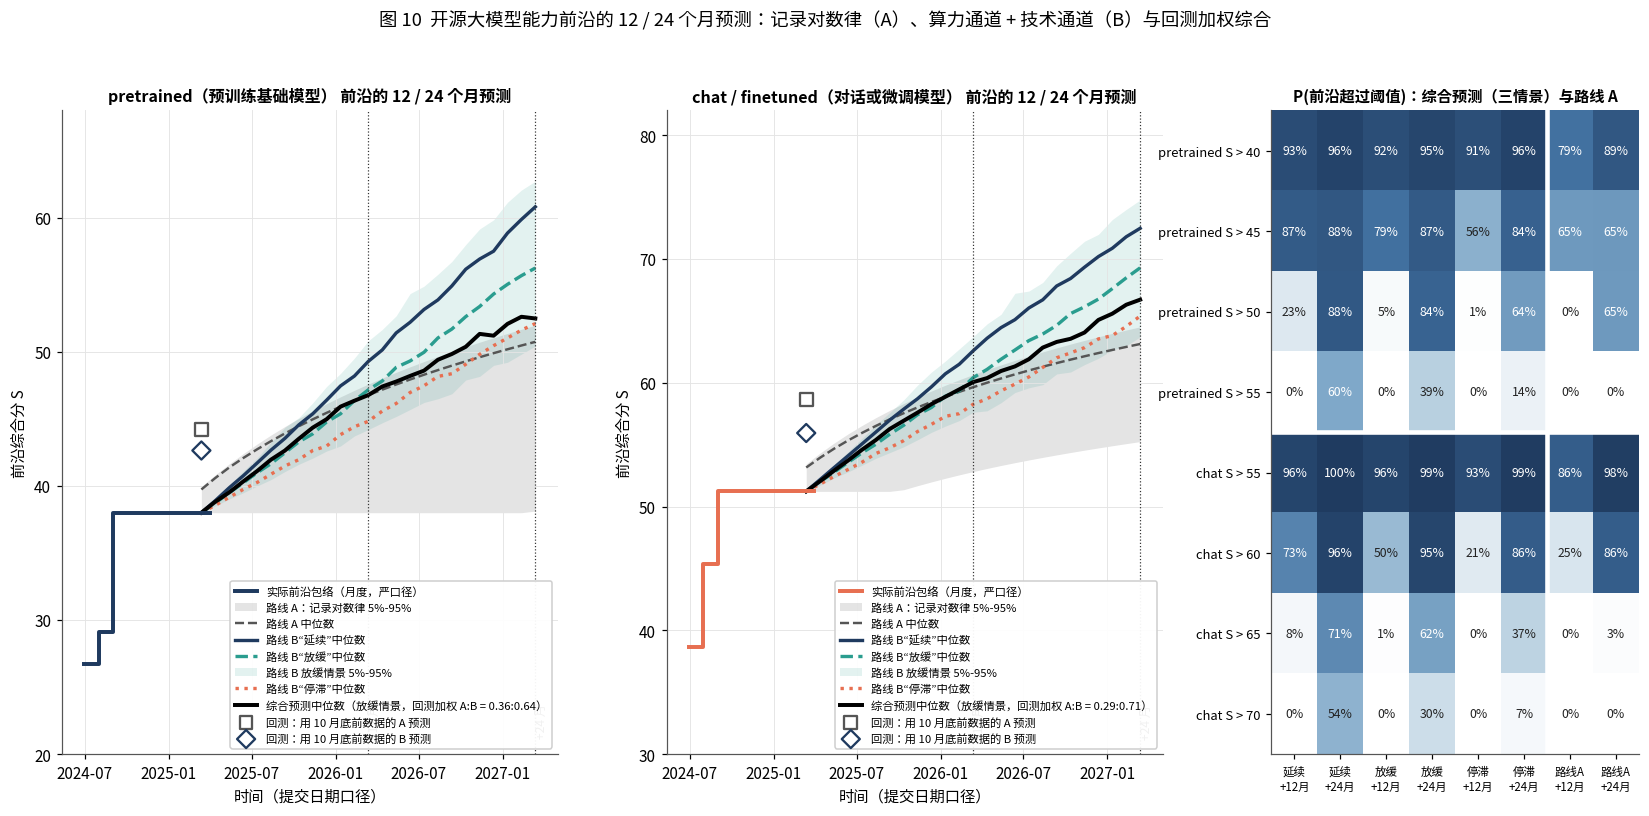

In [7]:
# ============ 6. 前沿预测 ============
H = [12, 24]; tau_end = float(LB['tau'].max()); FC = []
def env_monthly(df):
    d = df.sort_values('date_sub'); m = d.groupby(d['date_sub'].dt.to_period('M'))['S'].max().cummax()
    t = np.array([(p.to_timestamp(how='end') - T0).days / 30.4375 for p in m.index]); return t, m.values
def fit_loglaw(t, F):
    X = np.column_stack([np.ones(len(t)), np.log1p(t)]); b, *_ = np.linalg.lstsq(X, logit(np.clip(F / 100, 1e-3, 1 - 1e-3)), rcond=None); return b
def predA(b, t): return 100 * expit(b[0] + b[1] * np.log1p(t))
def fit_compute_reg(mc):
    X = np.column_stack([np.ones(len(mc)), np.log(mc['C']), mc['tau_pub'], (mc['type'] == 'chat/finetuned').astype(float)]); y = mc['y'].values
    b, *_ = np.linalg.lstsq(X, y, rcond=None); bo = np.array([np.linalg.lstsq(X[idx], y[idx], rcond=None)[0] for idx in (RNG.integers(0, len(mc), len(mc)) for _ in range(300))]); return b, bo
G_phys_ci = GR['2023.5 至数据末']['ci_mult']; sd_lnG = (np.log(G_phys_ci[1]) - np.log(G_phys_ci[0])) / (2 * 1.96)
def draw_G(sname, n): G = SCEN[sname]; return np.ones(n) if sname.startswith('停滞') else np.exp(RNG.normal(np.log(G), sd_lnG * (0.5 if sname.startswith('放缓') else 1.0), n))
def predB(F_now, h, sname, bo, n_mc=3000):
    bb = bo[RNG.integers(0, len(bo), n_mc)]; gp = draw_G(sname, n_mc)
    y = logit(F_now / 100) + bb[:, 1] * (h / 12) * np.log(gp) + bb[:, 2] * h; return np.maximum(100 * expit(y), F_now)

# ---- 路线 A ----
A_RES = {}
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]; t, F = env_monthly(d); bA = fit_loglaw(t, F); F_now = float(F[-1])
    boots = np.array([fit_loglaw(*env_monthly(d.iloc[RNG.integers(0, len(d), len(d))])) for _ in range(300)])
    pred = {h: np.maximum(predA(boots.T, tau_end + h), F_now) for h in H}; A_RES[g] = {'b': bA, 'boot': boots, 'pred': pred, 't': t, 'F': F, 'F_now': F_now}
    for h in H: FC.append({'路线': 'A 记录对数律', '类型': g, '情景': '趋势延续', '月数': h, '中位数': float(np.median(pred[h])), '5%': float(np.percentile(pred[h], 5)), '95%': float(np.percentile(pred[h], 95))})
    print('路线 A %s: logit(F) = %.3f + %.3f ln(1+tau) -> 12 月 %.1f [%.1f, %.1f], 24 月 %.1f [%.1f, %.1f]' % (g, bA[0], bA[1], np.median(pred[12]), np.percentile(pred[12], 5), np.percentile(pred[12], 95), np.median(pred[24]), np.percentile(pred[24], 5), np.percentile(pred[24], 95)))
# ---- 路线 B ----
B_RES = {}
print('路线 B 系数（长周期 C4 匹配样本）: beta_C = %.3f [%.3f, %.3f], gamma_C = %.4f/月 [%.4f, %.4f]' % (bc[1], *np.percentile(bo_c[:, 1], [2.5, 97.5]), bc[2], *np.percentile(bo_c[:, 2], [2.5, 97.5])))
for g in ('pretrained', 'chat/finetuned'):
    F_now = A_RES[g]['F_now']
    for sname in SCEN:
        for h in H:
            S_mc = predB(F_now, h, sname, bo_c); B_RES[(g, sname, h)] = S_mc
            FC.append({'路线': 'B 算力通道 + 技术通道', '类型': g, '情景': sname, '月数': h, '中位数': float(np.median(S_mc)), '5%': float(np.percentile(S_mc, 5)), '95%': float(np.percentile(S_mc, 95))})

# ---- 截断回测 ----
cut = pd.Timestamp('2024-10-31'); BT = []; W = {}
for g in ('pretrained', 'chat/finetuned'):
    d_all = LB[(LB['type'] == g) & LB['open_strict']]; d = d_all[d_all['date_sub'] <= cut]; tau_c = float(d['tau'].max()); h_bt = tau_end - tau_c; actual = env_monthly(d_all)[1][-1]
    t, F = env_monthly(d); bA = fit_loglaw(t, F); pA = max(float(predA(bA, tau_end)), float(F[-1]))
    mc_cut = MC[MC['date_sub'] <= cut]; b_cut, bo_cut = fit_compute_reg(mc_cut); S_mc = predB(float(F[-1]), h_bt, '延续（最近段拟合）', bo_cut); pB = float(np.median(S_mc))
    eA, eB = pA - actual, pB - actual; W[g] = (1 / max(eA, 0.3) ** 2, 1 / max(eB, 0.3) ** 2); W[g] = (W[g][0] / sum(W[g]), W[g][1] / sum(W[g]))
    BT.append({'类型': g, '截断日期': cut.date(), '截断时前沿': float(F[-1]), '预测提前量(月)': round(h_bt, 1), '实际前沿(数据末)': actual, '路线 A 预测': pA, '路线 A 误差': eA, '路线 B 预测(延续)': pB, '路线 B 误差': eB, '路线 B 90% 区间': '[%.1f, %.1f]' % (np.percentile(S_mc, 5), np.percentile(S_mc, 95)), '综合权重 (A, B)': '(%.2f, %.2f)' % W[g]})
BTDF = pd.DataFrame(BT); print('\n截断回测（用 %s 前的数据预测 %s 的前沿）:' % (cut.date(), LB['date_sub'].max().date())); display(BTDF); BTDF.to_csv(TAB / 'backtest.csv', index=False, encoding='utf-8-sig')
# ---- 综合预测（按回测误差加权的混合分布） ----
for g in ('pretrained', 'chat/finetuned'):
    for sname in SCEN:
        for h in H:
            nA = int(round(3000 * W[g][0])); mix = np.r_[RNG.choice(A_RES[g]['pred'][h], nA), RNG.choice(B_RES[(g, sname, h)], 3000 - nA)]; B_RES[(g, '综合:' + sname, h)] = mix
            FC.append({'路线': '综合（回测加权）', '类型': g, '情景': sname, '月数': h, '中位数': float(np.median(mix)), '5%': float(np.percentile(mix, 5)), '95%': float(np.percentile(mix, 95))})
FCDF = pd.DataFrame(FC); FCDF.to_csv(TAB / 'frontier_forecast.csv', index=False, encoding='utf-8-sig')
print('\n前沿预测汇总（综合分 S，严口径；当前前沿 pretrained %.1f / chat %.1f）:' % (A_RES['pretrained']['F_now'], A_RES['chat/finetuned']['F_now'])); display(FCDF.pivot_table(index=['类型', '路线', '情景'], columns='月数', values=['中位数', '5%', '95%']).round(1))

# ---- 损失通道交叉核对 ----
G_alg_draws = np.exp(12 * bo_c[:, 2] / bo_c[:, 1]); G_alg_draws = G_alg_draws[np.isfinite(G_alg_draws) & (G_alg_draws > 0.5) & (G_alg_draws < 30)]
rows = []
for g, chat_ in (('pretrained', 0), ('chat/finetuned', 1)):
    F_now = A_RES[g]['F_now']
    for sname in SCEN:
        for h in H:
            n_mc = 3000; ga = G_alg_draws[RNG.integers(0, len(G_alg_draws), n_mc)]; gp = draw_G(sname, n_mc)
            dL = L_star(C_ANCHOR_LB) - L_star(C_ANCHOR_LB * (gp * ga) ** (h / 12)); bb = BOOT_B[RNG.integers(0, len(BOOT_B), n_mc), 1]
            S_loss = 100 * expit(logit(F_now / 100) + bb * dL); tot = np.median(B_RES[(g, sname, h)])
            rows.append({'类型': g, '情景': sname, '月数': h, '当前前沿': F_now, '仅损失通道的前沿(中位)': float(np.median(S_loss)), '损失通道增量': float(np.median(S_loss)) - F_now, '路线 B 总增量': tot - F_now, '非损失介导的技术进步(差)': (tot - F_now) - (float(np.median(S_loss)) - F_now), '损失下降 dL(中位)': float(np.median(dL))})
LOSSCH = pd.DataFrame(rows); print('\n损失通道交叉核对（C_anchor = %.1e，G_alg 中位 x%.1f/年）:' % (C_ANCHOR_LB, np.median(G_alg_draws))); display(LOSSCH); LOSSCH.to_csv(TAB / 'loss_channel_crosscheck.csv', index=False, encoding='utf-8-sig')

# ---- 概率矩阵 ----
THR = {'pretrained': [40, 45, 50, 55], 'chat/finetuned': [55, 60, 65, 70]}; PL = []
for g in ('pretrained', 'chat/finetuned'):
    for h in H:
        for sname in SCEN:
            for thr in THR[g]: PL.append({'类型': g, '月数': h, '情景': '综合:' + sname, '阈值': thr, 'P': float((B_RES[(g, '综合:' + sname, h)] > thr).mean())})
        for thr in THR[g]: PL.append({'类型': g, '月数': h, '情景': 'A 记录对数律', '阈值': thr, 'P': float((A_RES[g]['pred'][h] > thr).mean())})
PLDF = pd.DataFrame(PL); PLDF.to_csv(TAB / 'probability_ladder.csv', index=False, encoding='utf-8-sig')

# ---- 图 10：前沿预测扇形图 + 概率矩阵 ----
fig = plt.figure(figsize=(18.5, 7.6)); gs = gridspec.GridSpec(1, 3, width_ratios=[1.35, 1.35, 1.0], wspace=0.24)
hgrid = np.linspace(0, 24, 25); SC_COL = {list(SCEN)[0]: C_NAVY, list(SCEN)[1]: C_TEAL, list(SCEN)[2]: C_CORAL}; SC_LS = {list(SCEN)[0]: '-', list(SCEN)[1]: '--', list(SCEN)[2]: ':'}
for gi, g in enumerate(('pretrained', 'chat/finetuned')):
    ax = fig.add_subplot(gs[gi]); c = COL_TYPE[g]; t, F = A_RES[g]['t'], A_RES[g]['F']; F_now = A_RES[g]['F_now']
    xs = [T0 + pd.Timedelta(days=30.4375 * v) for v in t]; ax.step(xs, F, where='pre', color=c, lw=2.6, label='实际前沿包络（月度，严口径）', zorder=5)
    fut = [T0 + pd.Timedelta(days=30.4375 * (tau_end + h_)) for h_ in hgrid]; bo = A_RES[g]['boot']
    PA = np.array([np.maximum(predA(bo.T, tau_end + h_), F_now) for h_ in hgrid]); ax.fill_between(fut, np.percentile(PA, 5, axis=1), np.percentile(PA, 95, axis=1), color=C_GREY, alpha=0.28, lw=0, label='路线 A：记录对数律 5%-95%'); ax.plot(fut, np.median(PA, axis=1), color='#555555', lw=1.6, ls='--', label='路线 A 中位数')
    for sname in SCEN:
        PB = np.array([predB(F_now, h_, sname, bo_c, n_mc=800) for h_ in hgrid]); ax.plot(fut, np.median(PB, axis=1), color=SC_COL[sname], lw=2.2, ls=SC_LS[sname], label='路线 B“%s”中位数' % sname.split('（')[0])
        if sname.startswith('放缓'): ax.fill_between(fut, np.percentile(PB, 5, axis=1), np.percentile(PB, 95, axis=1), color=SC_COL[sname], alpha=0.13, lw=0, label='路线 B 放缓情景 5%-95%')
    PM = np.array([np.r_[RNG.choice(np.maximum(predA(bo.T, tau_end + h_), F_now), int(600 * W[g][0])), RNG.choice(predB(F_now, h_, '放缓（对数增长率减半）', bo_c, n_mc=800), 600 - int(600 * W[g][0]))] for h_ in hgrid])
    ax.plot(fut, np.median(PM, axis=1), color='black', lw=2.6, label='综合预测中位数（放缓情景，回测加权 A:B = %.2f:%.2f）' % W[g])
    bt = BTDF[BTDF['类型'] == g].iloc[0]; xe = T0 + pd.Timedelta(days=30.4375 * tau_end)
    ax.scatter([xe], [bt['路线 A 预测']], marker='s', s=70, facecolors='none', edgecolors='#555555', linewidths=1.5, zorder=6, label='回测：用 10 月底前数据的 A 预测'); ax.scatter([xe], [bt['路线 B 预测(延续)']], marker='D', s=70, facecolors='none', edgecolors=C_NAVY, linewidths=1.5, zorder=6, label='回测：用 10 月底前数据的 B 预测')
    for h_ in H: ax.axvline(T0 + pd.Timedelta(days=30.4375 * (tau_end + h_)), color='#333333', lw=0.8, ls=':'); ax.text(T0 + pd.Timedelta(days=30.4375 * (tau_end + h_)), (31 if g == 'chat/finetuned' else 21), ' +%d 月' % h_, fontsize=8, rotation=90, va='bottom')
    ax.set_ylim(30 if g == 'chat/finetuned' else 20, 82 if g == 'chat/finetuned' else 68); ax.xaxis.set_major_locator(mpl.dates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m')); ax.set_xlabel('时间（提交日期口径）'); ax.set_ylabel('前沿综合分 S')
    ax.legend(frameon=True, fontsize=7.4, loc='lower right', facecolor='white', framealpha=0.95); ax.set_title('%s 前沿的 12 / 24 个月预测' % NAME_TYPE[g], fontsize=10.5)
ax = fig.add_subplot(gs[2]); ax.grid(False)
cols_ = [('综合:' + s_, h_) for s_ in SCEN for h_ in H] + [('A 记录对数律', h_) for h_ in H]
rows_ = [(g, thr) for g in ('pretrained', 'chat/finetuned') for thr in THR[g]]
M = np.array([[PLDF[(PLDF['类型'] == g) & (PLDF['阈值'] == thr) & (PLDF['情景'] == s_) & (PLDF['月数'] == h_)]['P'].iloc[0] for (s_, h_) in cols_] for (g, thr) in rows_])
ax.imshow(M, cmap=CMAP_DENS, vmin=0, vmax=1, aspect='auto')
for i_ in range(M.shape[0]):
    for j_ in range(M.shape[1]): ax.text(j_, i_, '%.0f%%' % (100 * M[i_, j_]), ha='center', va='center', fontsize=8, color='white' if M[i_, j_] > 0.6 else '#222222')
ax.set_xticks(range(len(cols_))); ax.set_xticklabels(['%s\n+%d月' % ('路线A' if s_.startswith('A') else s_.replace('综合:', '').split('（')[0], h_) for (s_, h_) in cols_], fontsize=7.5, rotation=0)
ax.set_yticks(range(len(rows_))); ax.set_yticklabels(['%s S > %d' % ('pretrained' if g == 'pretrained' else 'chat', thr) for (g, thr) in rows_], fontsize=8.5)
ax.axhline(len(THR['pretrained']) - 0.5, color='white', lw=3); ax.axvline(len(cols_) - 2.5, color='white', lw=3)
ax.set_title('P(前沿超过阈值)：综合预测（三情景）与路线 A', fontsize=10)
fig.suptitle('图 10  开源大模型能力前沿的 12 / 24 个月预测：记录对数律（A）、算力通道 + 技术通道（B）与回测加权综合', fontsize=12, y=1.0)
savefig('fig10_frontier_forecast_fan.png'); plt.show()

## 7. 稳健性：口径、时间轴、分位数水平与综合分定义

把主要估计（非规模进步率 $\gamma$、非规模占比、12 个月前沿预测）在下列替代口径下重做：开源口径（严 / 宽）、时间轴（提交日期 / Epoch 发布日期 / C8 评测时间）、前沿分位数（0.85 / 0.9 / 0.95）、综合分（C1 `Average` / C8 重建的 $S^{C8}$）。若结论的方向与量级不随口径改变，则可写入结论。

稳健性：非规模进步率在不同口径下的估计
已保存 output_q4/tables/q4_summary.json


,类型,口径,n,gamma/月,年参数倍数
0,pretrained,基准：严口径 / 提交日期 / q=0.9 / C1 Average,241,0.0231,1.9136
1,pretrained,宽口径,330,0.0206,1.7796
2,pretrained,q = 0.85,241,0.0241,2.0648
3,pretrained,q = 0.95,241,0.0100,1.3428
4,pretrained,综合分 = C8 重建 S_C8,118,0.0117,1.4263
5,pretrained,时间轴 = C8 评测时间,118,0.0260,2.1800
6,pretrained,时间轴 = Epoch 发布日期（匹配子集）,57,0.0292,2.3053
7,chat/finetuned,基准：严口径 / 提交日期 / q=0.9 / C1 Average,2257,0.0637,5.8091
8,chat/finetuned,宽口径,4222,0.0584,4.8940
9,chat/finetuned,q = 0.85,2257,0.0712,7.2116


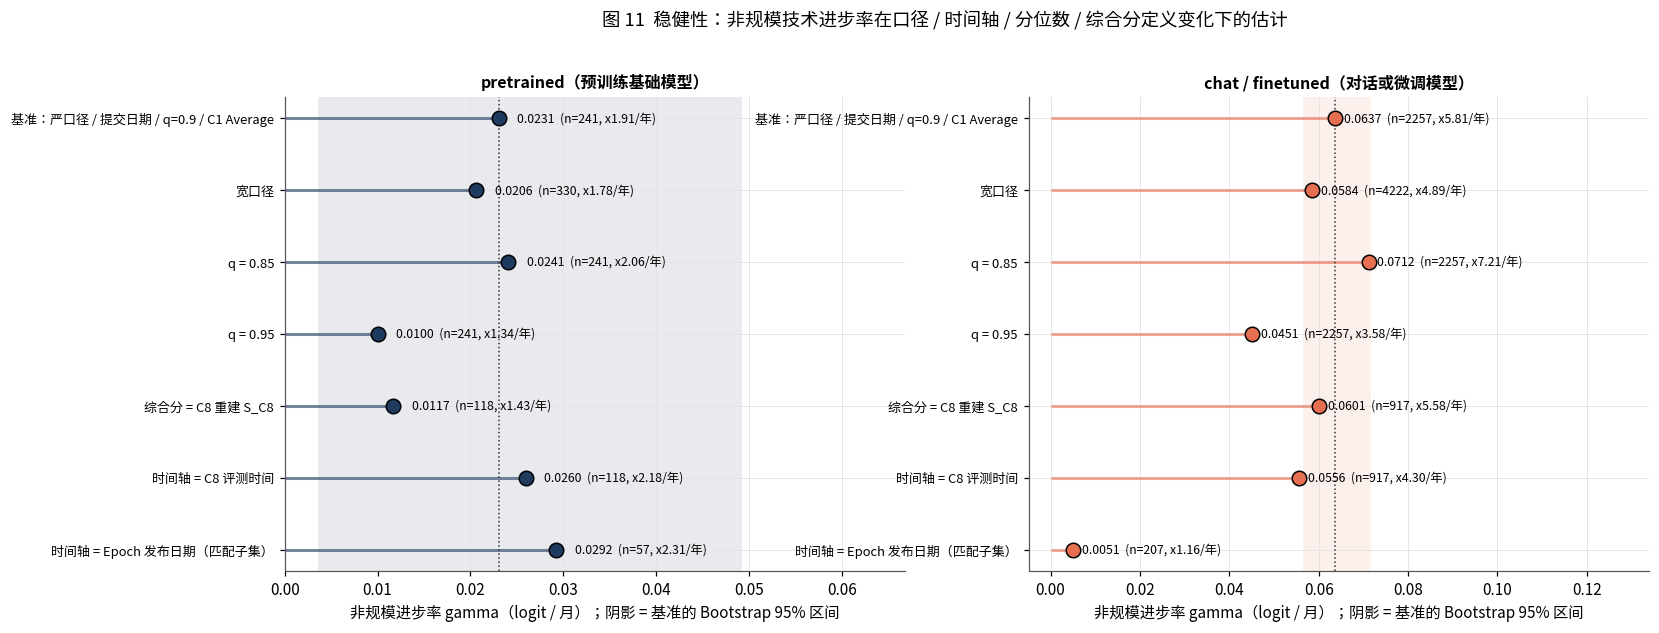

In [8]:
# ============ 7. 稳健性分析 ============
def fit_gamma(df, q=0.9, ycol='y', tcol='tau'):
    X = design(df['lnN'].values, df[tcol].values); b = quantreg(X, df[ycol].values, q); Nref = float(np.exp(np.median(df['lnN']))); bN = b[1] + 2 * b[2] * np.log(Nref)
    return b[3], float(np.exp(12 * b[3] / bN)) if bN > 0 else np.nan
LB['tau_pub'] = (LB['date_pub'] - T0).dt.days / 30.4375; LB['tau_eval'] = (LB['date_eval'] - T0).dt.days / 30.4375; LB['y_c8'] = logit(np.clip(LB['S_C8'] / 100, 1e-3, 1 - 1e-3))
rows = []
for g in ('pretrained', 'chat/finetuned'):
    base = LB[(LB['type'] == g)]
    variants = [('基准：严口径 / 提交日期 / q=0.9 / C1 Average', base[base.open_strict], 0.9, 'y', 'tau'), ('宽口径', base, 0.9, 'y', 'tau'), ('q = 0.85', base[base.open_strict], 0.85, 'y', 'tau'), ('q = 0.95', base[base.open_strict], 0.95, 'y', 'tau'),
                ('综合分 = C8 重建 S_C8', base[base.open_strict & base.S_C8.notna()], 0.9, 'y_c8', 'tau'), ('时间轴 = C8 评测时间', base[base.open_strict & base.tau_eval.notna()], 0.9, 'y', 'tau_eval'), ('时间轴 = Epoch 发布日期（匹配子集）', base[base.open_strict & base.tau_pub.notna()], 0.9, 'y', 'tau_pub')]
    for name, d, q, yc, tc in variants:
        if len(d) < 40: rows.append({'类型': g, '口径': name, 'n': len(d), 'gamma/月': np.nan, '年参数倍数': np.nan}); continue
        gm, mult = fit_gamma(d, q, yc, tc); rows.append({'类型': g, '口径': name, 'n': len(d), 'gamma/月': gm, '年参数倍数': mult})
ROB = pd.DataFrame(rows); print('稳健性：非规模进步率在不同口径下的估计'); display(ROB); ROB.to_csv(TAB / 'robustness.csv', index=False, encoding='utf-8-sig')

# ---- 图 11：稳健性"点-线"图：各口径下 gamma 的估计（分类型） ----
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharey=False)
for ax, g in zip(axes, ('pretrained', 'chat/finetuned')):
    d = ROB[ROB['类型'] == g].reset_index(drop=True); c = COL_TYPE[g]
    ax.hlines(np.arange(len(d)), 0, d['gamma/月'], color=c, lw=2, alpha=0.6); ax.scatter(d['gamma/月'], np.arange(len(d)), s=90, color=c, edgecolor='black', zorder=4)
    for i, r in d.iterrows(): ax.text(r['gamma/月'] + 0.002, i, '%.4f  (n=%d, x%.2f/年)' % (r['gamma/月'], r['n'], r['年参数倍数']) if np.isfinite(r['gamma/月']) else '样本不足', va='center', fontsize=8)
    ax.axvline(FIT[g]['gamma'], color='#333333', lw=1, ls=':'); ax.axvspan(FIT[g]['gamma_ci'][0], FIT[g]['gamma_ci'][1], color=c, alpha=0.1, lw=0)
    ax.set_yticks(np.arange(len(d))); ax.set_yticklabels(d['口径'], fontsize=8.5); ax.invert_yaxis(); ax.set_xlabel('非规模进步率 gamma（logit / 月）；阴影 = 基准的 Bootstrap 95% 区间'); ax.set_xlim(min(0, d['gamma/月'].min() - 0.01), max(d['gamma/月'].max(), 0) * 1.6 + 0.02)
    ax.set_title(NAME_TYPE[g], fontsize=10.5)
fig.suptitle('图 11  稳健性：非规模技术进步率在口径 / 时间轴 / 分位数 / 综合分定义变化下的估计', fontsize=12, y=1.02)
savefig('fig11_robustness_dotline.png'); plt.show()

# 结果汇总输出
summary = {'criteria': {'composite': 'C1 Average (6-dim equal-weight, normalized); validated by C8-rebuilt S_C8', 'open_source_strict': sorted(LIC_OK), 'types': {'pretrained': ['pretrained', 'continuously pretrained'], 'chat/finetuned': ['chat', 'fine-tuned', 'merges']}, 'time_axis': 'C1 submission date (main); Epoch publication date & C8 eval timestamp as sensitivity'},
           'decomposition': DECDF.to_dict(orient='records'), 'production_function': {g: {k: v for k, v in FIT[g].items() if k not in ('b', 'ols')} for g in FIT}, 'compute_based_alg_progress': ALG, 'compute_growth_scenarios': SCEN, 'bridge': {'theta': TH_B.tolist(), 'sigma_tier': SIG}, 'forecast': FC, 'backtest': BTDF.to_dict(orient='records'), 'loss_channel_crosscheck': LOSSCH.to_dict(orient='records')}
json.dump(summary, open(TAB / 'q4_summary.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=str); print('已保存 output_q4/tables/q4_summary.json')

## 8. 问题四小结

**度量与口径**：综合能力取排行榜 6 维等权平均 $S$（0–100，logit 尺度建模），并用 C8 的 45 个逐任务结果按"经验随机基线归一 + 样本量加权"独立重建 $S^{C8}$ 作校验；开源严口径 = 权重开源且许可证在允许研究与复现的白名单内（`other` / 缺失剔除），宽口径 = 全部权重开源模型，并与 Epoch AI 的开源权重字段交叉核对；模型类型分 pretrained 与 chat/finetuned 两条前沿；时间轴主用 C1 提交日期，Epoch 发布日期与 C8 评测时间作敏感性。

**规模 vs 非规模的分离**：能力生产函数 $\mathrm{logit}(S)=\beta_0+\beta_1\ln N+\beta_2(\ln N)^2+\gamma\tau$ 的前沿分位回归（$q=0.9$）识别出控制规模后的时间漂移 $\gamma$，转化为"参数需求半衰期"与"每年等价参数倍数"；Shapley 分解给出 2024-06 至 2025-03 前沿变化中规模与非规模的贡献占比（见表与图 6）；以训练算力为规模变量的长周期估计给出算法进步的有效算力年增倍数（C4 匹配样本）。C8 逐任务分析进一步显示增益集中在数学与 BBH 推理子任务，而知识型任务（MMLU-PRO、GPQA）更依赖规模。

**桥接与预测**：C6 的 logistic 桥接把问题三的最优损失 $L^\star(C)$ 翻译为可达分数，按可比性分层报告映射误差；路线 A（记录过程的对数律 + 模型级 Bootstrap）与路线 B（长周期估计的算力通道 + 技术通道 × 三档算力情景）给出 12 / 24 个月的前沿区间，截断回测给出两条路线的样本外误差并据此加权综合，超阈值概率矩阵给出决策用的概率；损失通道交叉核对表明经预训练损失介导的进步只占路线 B 总增量的一小部分，其余来自不经损失介导的后训练与数据工程进步——这也是桥接映射误差对结论影响有限的原因（映射只用于交叉核对，不是预测主链）。"算力增长放缓"情景下前沿的继续上升主要由技术通道支撑。

**输出文件**（`output_q4/`）：`figures/fig01–fig11*.png`；`tables/leaderboard_analysis_table.csv`、`open_source_criteria_counts.csv`、`c8_task_level_analysis.csv`、`half_life_by_scale.csv`、`shapley_decomposition.csv`、`production_function_fits.json`、`leaderboard_matched_epoch_compute.csv`、`compute_growth_fits.csv`、`bridge_fit.csv`、`bridge_params.json`、`frontier_forecast.csv`、`backtest.csv`、`loss_channel_crosscheck.csv`、`probability_ladder.csv`、`robustness.csv`、`q4_summary.json`。